# Baghoosh Resort – Sales & Pricing Analysis

**Company:** Al Riyadh Real Estate (fictional Egyptian developer) · **Project:** Baghoosh Resort, North Coast · **Currency:** EGP
**Data:** 15 synthetic department exports (ERP, CRM, Finance, Commercial, GIS, PMO, Market) in `data/raw/`.

**Business goal:** understand what drives Phase 1 unit sales and pricing, and support pricing decisions.

**Notebook map**
1. Setup and imports
2. Extract – load all raw files
3. Data cleaning
4. Data wrangling / transform
5. Load – save the cleaned dataset
6. Exploratory data analysis (EDA)
7. Visualization
8. Key findings and recommendations
9. Machine learning model (will a unit sell?)

# 1. Setup and imports

### 1.1 Import libraries
**What:** loads the libraries used in this notebook.
**Expected output:** nothing printed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### 1.2 CONFIG – paths and settings
**What:** all file paths, dates and fixed settings in one place.
**Why:** if something changes (for example a folder name) I only need to change it here.
The paths are relative, so the notebook works on any computer as long as it is run from the project folder.
**Expected output:** `True` if the raw data folder is found.

In [2]:
import os

# File paths
RAW_FOLDER = "data/raw/"
CLEAN_FILE = "data/cleaned_data.csv"
LEADS_FILE = "data/leads_clean.csv"
MONTHLY_FILE = "data/monthly_sales.csv"

# Important dates
REPORT_DATE = pd.to_datetime("2025-12-30")   # last date in the data
LAUNCH_DATE = pd.to_datetime("2024-04-15")   # Phase 1 sales started on this day

# Chart colours
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#898781"

os.makedirs("models", exist_ok=True)   # folder for the model in Step 3
print(os.path.exists(RAW_FOLDER))

True


### 1.3 Display and chart settings
**What:** shows numbers with thousand separators and gives all charts the same simple style.
**Expected output:** nothing printed.

In [3]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

### 1.4 Small helper functions
**What:** three functions I use many times while cleaning:
- `parse_dates` – the files mix date formats (`2024-04-27`, `20240427`, `27/04/2024`, `27-Apr-2024`). It tries each format one by one.
- `area_to_number` – turns text like `"105 sqm"` or `"76 m2"` into the number 105.
- `percent_to_number` – turns `"18%"` into 0.18 (values that are already 0.18 stay the same).

**Expected output:** nothing printed.

In [4]:
def parse_dates(column):
    text = column.astype(str).str.strip()
    result = pd.to_datetime(text, format="%Y-%m-%d", errors="coerce")
    # try the other formats only for the values that are still empty
    other_formats = ["%Y-%m-%d %H:%M:%S", "%Y%m%d", "%d/%m/%Y", "%d-%m-%Y", "%d-%b-%Y"]
    for date_format in other_formats:
        result = result.fillna(pd.to_datetime(text, format=date_format, errors="coerce"))
    return result


def area_to_number(column):
    # remove the unit first, otherwise "76 m2" would become 762
    text = column.astype(str).str.replace("sqm", "").str.replace("m2", "").str.strip()
    return pd.to_numeric(text, errors="coerce").astype(float)


def percent_to_number(column):
    text = column.astype(str)
    has_percent_sign = text.str.contains("%")
    numbers = pd.to_numeric(text.str.replace("%", ""))
    numbers[has_percent_sign] = numbers[has_percent_sign] / 100
    return numbers

# 2. Extract – load all raw files

### 2.1 Load the files
**What:** reads all 15 files. Three Excel files have two sheets each, so I get 17 tables.
- CSV files use `encoding="utf-8-sig"` to remove a hidden character at the start of the file.
- The QS rates file has a title above the table, so the header is on row 3 (`header=2`).

**Expected output:** nothing printed.

In [5]:
units_raw = pd.read_excel(RAW_FOLDER + "ERP_Unit_Master.xlsx")
buildings_raw = pd.read_excel(RAW_FOLDER + "ERP_Project_Structure.xlsx")
price_list_raw = pd.read_csv(RAW_FOLDER + "COM_Price_List.csv", encoding="utf-8-sig")
payment_plans_raw = pd.read_excel(RAW_FOLDER + "COM_Payment_Plans.xlsx")
margins_raw = pd.read_excel(RAW_FOLDER + "COM_Pricing_Policy.xlsx", sheet_name="Margins")
premiums_raw = pd.read_excel(RAW_FOLDER + "COM_Pricing_Policy.xlsx", sheet_name="Premiums")
qs_rates_raw = pd.read_excel(RAW_FOLDER + "QS_Construction_Rates.xlsx", header=2)
brokers_raw = pd.read_excel(RAW_FOLDER + "CRM_Brokers.xlsx")
leads_raw = pd.read_csv(RAW_FOLDER + "CRM_Leads.csv", encoding="utf-8-sig")
viewings_raw = pd.read_csv(RAW_FOLDER + "CRM_Viewings.csv", encoding="utf-8-sig")
reservations_raw = pd.read_csv(RAW_FOLDER + "CRM_Reservations.csv", encoding="utf-8-sig")
contracts_raw = pd.read_csv(RAW_FOLDER + "FIN_Sales_Contracts.csv", encoding="utf-8-sig")
ledger_raw = pd.read_csv(RAW_FOLDER + "FIN_Cost_Ledger.csv", encoding="utf-8-sig")
gis_raw = pd.read_csv(RAW_FOLDER + "GIS_Distances.csv", encoding="utf-8-sig")
pmo_raw = pd.read_csv(RAW_FOLDER + "PMO_Build_Progress.csv", encoding="utf-8-sig")
rental_comps_raw = pd.read_excel(RAW_FOLDER + "MKT_Market_Comps.xlsx", sheet_name="Rental_Comps")
price_index_raw = pd.read_excel(RAW_FOLDER + "MKT_Market_Comps.xlsx", sheet_name="Price_Index")

### 2.2 Quick overview of every table
**What:** rows, columns, missing cells and duplicate rows for each table.
**Why:** a first look at where the problems are.
**Expected output:** one row per table.

In [6]:
all_tables = {
    "units": units_raw, "buildings": buildings_raw, "price_list": price_list_raw,
    "payment_plans": payment_plans_raw, "margins": margins_raw, "premiums": premiums_raw,
    "qs_rates": qs_rates_raw, "brokers": brokers_raw, "leads": leads_raw, "viewings": viewings_raw,
    "reservations": reservations_raw, "contracts": contracts_raw, "ledger": ledger_raw, "gis": gis_raw,
    "pmo": pmo_raw, "rental_comps": rental_comps_raw, "price_index": price_index_raw,
}

overview_rows = []
for name, table in all_tables.items():
    overview_rows.append([name, table.shape[0], table.shape[1], table.isna().sum().sum(), table.duplicated().sum()])

overview = pd.DataFrame(overview_rows, columns=["table", "rows", "columns", "missing_cells", "duplicate_rows"])
overview

,table,rows,columns,missing_cells,duplicate_rows
0,units,468,15,284,18
1,buildings,40,6,0,0
2,price_list,712,7,0,0
3,payment_plans,6,4,0,0
4,margins,6,4,0,0
5,premiums,5,2,0,0
6,qs_rates,8,4,7,0
7,brokers,12,3,0,0
8,leads,3054,7,150,0
9,viewings,819,5,0,0


### 2.3 Rename columns to snake_case
**What:** `Built-up Area sqm` becomes `built_up_area_sqm`, `Construction Completion %` becomes `construction_completion`.
**Why:** names without spaces and symbols are easier to type in code.
I make cleaned copies of the raw tables here, so the raw tables stay untouched.
**Expected output:** the new column names of the units table.

In [7]:
def clean_column_names(table):
    table = table.copy()
    table.columns = (table.columns.str.lower()
                     .str.replace("%", "")
                     .str.replace("-", "_")
                     .str.strip()
                     .str.replace(" ", "_"))
    return table


units = clean_column_names(units_raw)
buildings = clean_column_names(buildings_raw)
price_list = clean_column_names(price_list_raw)
payment_plans = clean_column_names(payment_plans_raw)
margins = clean_column_names(margins_raw)
premiums = clean_column_names(premiums_raw)
qs_rates = clean_column_names(qs_rates_raw)
brokers = clean_column_names(brokers_raw)
leads = clean_column_names(leads_raw)
viewings = clean_column_names(viewings_raw)
reservations = clean_column_names(reservations_raw)
contracts = clean_column_names(contracts_raw)
ledger = clean_column_names(ledger_raw)
gis = clean_column_names(gis_raw)
pmo = clean_column_names(pmo_raw)
rental_comps = clean_column_names(rental_comps_raw)
price_index = clean_column_names(price_index_raw)

print(units.columns.tolist())

['unit_id', 'building', 'unit_number', 'property_type', 'bedrooms', 'bathrooms', 'built_up_area_sqm', 'plot_area_sqm', 'view_type', 'sea_view', 'corner_unit', 'private_pool', 'furnished_status', 'availability_status', 'expected_handover_date']


# 3. Data cleaning

I clean one table at a time and print the shape before and after each step.

**Rules I follow**
- **Fix** a value only when another file proves the correct value.
- **Fill** a missing value with a median or the most common value when only a few rows are missing.
- **Drop** a row only when it is a duplicate or can't be linked to anything.
- If I can't know the real value, I use a label like `"Unknown"` instead of guessing.

## 3.1 Buildings

### 3.1.1 Fix cluster spellings
**What:** the cluster column has 11 spellings of 6 names (`SeaBreeze`, `Palm-Grove`, `palm grove` ...).
**Why:** `Palm Grove` and `palm grove` would be counted as two different clusters.
**How:** replace `-` with a space, use Title Case, then fix `Seabreeze`.
**Expected output:** shape before/after and 6 clusters.

In [8]:
print("Before:", buildings.shape)

buildings["cluster"] = buildings["cluster"].str.replace("-", " ").str.strip().str.title()
buildings["cluster"] = buildings["cluster"].replace({"Seabreeze": "Sea Breeze"})

print("After: ", buildings.shape)
buildings["cluster"].value_counts()

Before: (40, 6)
After:  (40, 6)


cluster
Sea Breeze      7
Coral Bay       7
Palm Grove      7
Sunset Hills    7
Azure Coast     6
Olive Grove     6
Name: count, dtype: int64

## 3.2 Lookup tables (pricing policy and QS rates)

### 3.2.1 Convert percentages stored as text
**What:** some cells are text like `"18%"` and others are numbers like `0.18`. I convert all of them to numbers.
I also read the cash discount from the policy table, so I don't type it by hand.
**Expected output:** the clean margins table and the cash discount (0.12).

In [9]:
margins["minimum_acceptable_margin"] = percent_to_number(margins["minimum_acceptable_margin"])
margins["target_gross_margin"] = percent_to_number(margins["target_gross_margin"])
premiums["premium"] = percent_to_number(premiums["premium"])

CASH_DISCOUNT = premiums.loc[premiums["feature"] == "Cash Discount", "premium"].values[0]
print("Cash discount:", CASH_DISCOUNT)
margins

Cash discount: 0.12


,property_type,minimum_acceptable_margin,target_gross_margin,property_type_premium
0,Apartment,0.18,0.32,0.00
1,Chalet,0.18,0.33,0.03
2,Townhouse,0.20,0.35,0.05
3,Villa,0.22,0.38,0.08
4,Duplex,0.20,0.34,0.04
5,Penthouse,0.20,0.35,0.06


### 3.2.2 Remove the notes rows from the QS rates
**What:** under the QS table there is a blank row and a notes row. They have no rate, so I drop them.
The note says: the finishing uplift applies to **Fully Furnished** units and the pool add-on is a lump sum per pool.
I use exactly that rule in Section 4.
**Expected output:** 8 rows -> 6 rows.

In [10]:
print("Before:", qs_rates.shape)
qs_rates = qs_rates.dropna(subset=["construction_cost_per_sqm"])
print("After: ", qs_rates.shape)
qs_rates

Before: (8, 4)
After:  (6, 4)


,property_type,construction_cost_per_sqm,private_pool_add_on,premium_finishing_uplift
0,Apartment,"20,000.00","800,000.00",0.12
1,Chalet,"21,000.00","800,000.00",0.12
2,Townhouse,"25,000.00","1,100,000.00",0.15
3,Villa,"28,000.00","1,500,000.00",0.18
4,Duplex,"23,000.00","900,000.00",0.14
5,Penthouse,"24,000.00","900,000.00",0.15


## 3.3 Price list

### 3.3.1 Find list prices that break the cash-price rule
**What:** the cash price should always be the list price minus 12%. I check that rule on every row.
**Expected output:** the number of rows that break the rule.

In [11]:
price_list["effective_date"] = parse_dates(price_list["effective_date"])

expected_cash = price_list["list_price"] * (1 - CASH_DISCOUNT)
broken_price = abs(price_list["cash_price"] - expected_cash) > price_list["list_price"] * 0.005   # 0.5% tolerance for rounding

print("Rows breaking the rule:", broken_price.sum(), "out of", len(price_list))
price_list[broken_price].head()

Rows breaking the rule: 16 out of 712


,unit_id,price_version,effective_date,list_price,cash_price,price_per_sqm,default_payment_plan
16,BGH-0006,2,2025-01-01,"206,920,000.00","18,208,960.00","82,111.00",15% Down + 7 Years
97,BGH-0042,1,2024-04-15,"42,610,000.00","3,749,680.00","65,575.00",20% Down + 5 Years
138,BGH-0062,1,2024-04-15,"49,530,000.00","4,358,640.00","81,197.00",15% Down + 7 Years
144,BGH-0065,1,2024-04-15,"73,330,000.00","6,453,040.00","77,189.00",10% Down + 6 Years
149,BGH-0068,2,2025-01-01,"4,623,000.00","7,072,560.00","84,600.00",20% Down + 5 Years


### 3.3.2 Rebuild the broken list prices
**What:** for those 16 rows I calculate the list price from the cash price: `list = cash / 0.88`, rounded to 1,000.
**Why the list price is the wrong one:** 10 list prices are about ×10 too big, and 6 are lower than their own cash price,
which is impossible. The cash prices look normal, so I trust them. Dropping the rows would lose price history.
**Expected output:** 0 rows still breaking the rule.

In [12]:
print("Before:", price_list.shape)
price_list.loc[broken_price, "list_price"] = (price_list.loc[broken_price, "cash_price"] / (1 - CASH_DISCOUNT)).round(-3)
print("After: ", price_list.shape)

expected_cash = price_list["list_price"] * (1 - CASH_DISCOUNT)
still_broken = abs(price_list["cash_price"] - expected_cash) > price_list["list_price"] * 0.005
print("Rows still breaking the rule:", still_broken.sum())

Before: (712, 7)
After:  (712, 7)
Rows still breaking the rule: 0


## 3.4 Units

### 3.4.1 Remove duplicate rows
**What:** drops rows that are exact copies.
**Why:** a duplicated unit would be counted twice.
**Expected output:** 468 -> 450 rows and 0 repeated unit IDs.

In [13]:
print("Before:", units.shape)
units = units.drop_duplicates()
print("After: ", units.shape)
print("Repeated unit IDs:", units["unit_id"].duplicated().sum())

Before: (468, 15)
After:  (450, 15)
Repeated unit IDs: 0


### 3.4.2 Fix property type spellings
**What:** 20 spellings (`CHALET`, `Town-house`, `Appartment`, `Chalet ` ...) become 6 types.
**How:** remove spaces, use Title Case, then fix the 3 spellings that are still wrong.
**Expected output:** 6 property types.

In [14]:
print("Before:", units.shape)

units["property_type"] = units["property_type"].str.strip().str.title()
units["property_type"] = units["property_type"].replace({
    "Appartment": "Apartment",
    "Town-House": "Townhouse",
    "Town House": "Townhouse",
})

print("After: ", units.shape)
units["property_type"].value_counts()

Before: (450, 15)
After:  (450, 15)


property_type
Apartment    125
Chalet       110
Townhouse     72
Villa         58
Duplex        50
Penthouse     35
Name: count, dtype: int64

### 3.4.3 Fix the Yes/No columns
**What:** `sea_view`, `corner_unit` and `private_pool` are written in 10 different ways (`Y`, `yes`, `True`, `1` ...).
I map them all to `Yes` / `No`.
**Expected output:** only Yes and No in each column, and 0 values that could not be mapped.

In [15]:
print("Before:", units.shape)

yes_no_map = {
    "Yes": "Yes", "yes": "Yes", "Y": "Yes", "True": "Yes", "1": "Yes",
    "No": "No", "no": "No", "N": "No", "False": "No", "0": "No",
}
for column in ["sea_view", "corner_unit", "private_pool"]:
    units[column] = units[column].astype(str).map(yes_no_map)
    print(column, "- values not mapped:", units[column].isna().sum())

print("After: ", units.shape)
units[["sea_view", "corner_unit", "private_pool"]].apply(pd.Series.value_counts)

Before: (450, 15)
sea_view - values not mapped: 0
corner_unit - values not mapped: 0
private_pool - values not mapped: 0
After:  (450, 15)


,sea_view,corner_unit,private_pool
No,216,346,369
Yes,234,104,81


### 3.4.4 Convert areas to numbers and find impossible areas
**What:** removes `sqm` / `m2` from the area columns and converts them to numbers.
Then I look for impossible built-up areas: zero, negative, or bigger than 1,000 sqm (the biggest real unit is about 450 sqm).
**Note:** `plot_area_sqm` is empty for Apartments, Duplexes and Penthouses on purpose – they have no private land.
**Expected output:** the 7 units with an impossible area.

In [16]:
units["built_up_area_sqm"] = area_to_number(units["built_up_area_sqm"])
units["plot_area_sqm"] = area_to_number(units["plot_area_sqm"])

impossible = (units["built_up_area_sqm"] <= 0) | (units["built_up_area_sqm"] > 1000)
units.loc[impossible, ["unit_id", "property_type", "bedrooms", "built_up_area_sqm"]]

,unit_id,property_type,bedrooms,built_up_area_sqm
29,BGH-0030,Duplex,3,"1,690.00"
71,BGH-0071,Townhouse,3,-197.00
154,BGH-0153,Townhouse,3,"1,700.00"
155,BGH-0154,Townhouse,3,"2,030.00"
193,BGH-0189,Apartment,2,0.00
212,BGH-0207,Chalet,2,-104.00
443,BGH-0427,Townhouse,4,-259.00


### 3.4.5 Fix the impossible areas
**What:** the price list has `price per sqm`, so `list price / price per sqm` gives back the real area.
A unit has several price versions, and a few `price per sqm` values are also wrong (see 3.4.8), so I take the **median**
over all versions of the unit.
The one Phase 2 unit has no price list, so it gets the median area of units with the same type and bedrooms.
**Expected output:** the 7 units with their fixed areas.

In [17]:
print("Before:", units.shape)

price_list["implied_area"] = price_list["list_price"] / price_list["price_per_sqm"]
area_from_price = price_list.groupby("unit_id")["implied_area"].median().round()

for unit in units.loc[impossible, "unit_id"]:
    row = units["unit_id"] == unit
    if unit in area_from_price.index:
        units.loc[row, "built_up_area_sqm"] = area_from_price[unit]
    else:
        # no price list -> median of the same property type and bedrooms
        unit_type = units.loc[row, "property_type"].values[0]
        unit_beds = units.loc[row, "bedrooms"].values[0]
        same_group = (units["property_type"] == unit_type) & (units["bedrooms"] == unit_beds) & (~impossible)
        units.loc[row, "built_up_area_sqm"] = units.loc[same_group, "built_up_area_sqm"].median()

price_list = price_list.drop(columns="implied_area")
print("After: ", units.shape)
units.loc[impossible, ["unit_id", "property_type", "bedrooms", "built_up_area_sqm"]]

Before: (450, 15)
After:  (450, 15)


,unit_id,property_type,bedrooms,built_up_area_sqm
29,BGH-0030,Duplex,3,169.00
71,BGH-0071,Townhouse,3,197.00
154,BGH-0153,Townhouse,3,170.00
155,BGH-0154,Townhouse,3,203.00
193,BGH-0189,Apartment,2,111.00
212,BGH-0207,Chalet,2,104.00
443,BGH-0427,Townhouse,4,239.50


### 3.4.6 Fill missing bathrooms, furnished status and view type
- **Bathrooms (16 missing, 3.6%)** -> median bathrooms of units with the same type and bedrooms. Bathrooms follow bedrooms closely.
- **Furnished status (16 missing, 3.6%)** -> the most common value, `Unfurnished` (it is the most common value for every property type).
- **View type (16 missing)** -> `"Unknown"`. I can't tell *Full* from *Partial* sea view from any other file, so I don't guess.

**Expected output:** missing values before and after – 0 after.

In [18]:
print("Before:", units.shape)
print(units[["bathrooms", "furnished_status", "view_type"]].isna().sum())

median_bathrooms = units.groupby(["property_type", "bedrooms"])["bathrooms"].transform("median").round()
units["bathrooms"] = units["bathrooms"].fillna(median_bathrooms)

most_common_furnished = units["furnished_status"].mode()[0]
units["furnished_status"] = units["furnished_status"].fillna(most_common_furnished)

units["view_type"] = units["view_type"].fillna("Unknown")

print("After: ", units.shape)
print(units[["bathrooms", "furnished_status", "view_type"]].isna().sum())

Before: (450, 15)
bathrooms           16
furnished_status    16
view_type           16
dtype: int64
After:  (450, 15)
bathrooms           0
furnished_status    0
view_type           0
dtype: int64


### 3.4.7 Fix handover dates
**What:** handover dates come in 4 formats and 16 are missing.
**Why this fill:** for every unit that has a date, the handover date is the same as its building's target completion date
(I check this below). So the building's date is a safe replacement.
**Expected output:** a 100% match rate and 0 missing dates.

In [19]:
print("Before:", units.shape)
units["expected_handover_date"] = parse_dates(units["expected_handover_date"])

building_dates = buildings.set_index("building")["target_completion"]
units["building_completion"] = units["building"].map(building_dates)

has_date = units["expected_handover_date"].notna()
same_date = units.loc[has_date, "expected_handover_date"] == units.loc[has_date, "building_completion"]
print("Handover date = building completion:", round(same_date.mean() * 100), "%")

units["expected_handover_date"] = units["expected_handover_date"].fillna(units["building_completion"])
units = units.drop(columns="building_completion")
print("After: ", units.shape)
print("Missing handover dates:", units["expected_handover_date"].isna().sum())

Before: (450, 15)
Handover date = building completion: 100 %
After:  (450, 15)
Missing handover dates: 0


### 3.4.8 Recalculate price per sqm in the price list
**What:** 43 price-list rows have a `price_per_sqm` that is not equal to `list price / area`
(for example BGH-0160 version 1 says 201,033 EGP/sqm, but 71.4M / 405 sqm = 176,202).
**Why recalculate:** price per sqm is calculated from two other columns, and both of them are now checked
(list price in 3.3, area in 3.4). So I recalculate it instead of trusting the stored value.
**Expected output:** 43 rows before -> 0 after.

In [20]:
print("Before:", price_list.shape)
price_list = price_list.merge(units[["unit_id", "built_up_area_sqm"]], on="unit_id", how="left")

correct_price_per_sqm = (price_list["list_price"] / price_list["built_up_area_sqm"]).round()
wrong = abs(correct_price_per_sqm - price_list["price_per_sqm"]) > price_list["price_per_sqm"] * 0.005
print("Rows with a wrong price per sqm:", wrong.sum())

price_list["price_per_sqm"] = correct_price_per_sqm
price_list = price_list.drop(columns="built_up_area_sqm")
print("After: ", price_list.shape)

Before: (712, 7)
Rows with a wrong price per sqm: 43
After:  (712, 7)


## 3.5 CRM – brokers, leads, viewings, reservations

### 3.5.1 Brokers: fix capitalisation
**What:** `COASTAL TEAM`, `cairo team`, `salma younes` -> Title Case.
**Expected output:** 3 sales teams.

In [21]:
print("Before:", brokers.shape)
brokers["broker_name"] = brokers["broker_name"].str.strip().str.title()
brokers["sales_team"] = brokers["sales_team"].str.strip().str.title()
print("After: ", brokers.shape)
brokers["sales_team"].value_counts()

Before: (12, 3)
After:  (12, 3)


sales_team
Coastal Team       4
Cairo Team         4
Alexandria Team    4
Name: count, dtype: int64

### 3.5.2 Leads: remove duplicates
**What:** 117 leads are copies of another lead with a new Lead ID (same date, customer, source, broker, unit and status).
**Why:** duplicates make conversion rates look worse. After removing them, the number of `Won` leads (144) is the same as the
number of contracts (144), which tells me this is the right rule.
I also check that no viewing or reservation uses one of the removed IDs.
**Expected output:** 3,054 -> 2,937 rows.

In [22]:
print("Before:", leads.shape)
lead_columns = ["created_date", "customer_name", "lead_source", "broker_id", "unit_id", "lead_status"]

removed_ids = leads.loc[leads.duplicated(subset=lead_columns), "lead_id"]
print("Viewings using a removed lead:", viewings["lead_id"].isin(removed_ids).sum())
print("Reservations using a removed lead:", reservations["lead_id"].isin(removed_ids).sum())

leads = leads.drop_duplicates(subset=lead_columns)
print("After: ", leads.shape)
print("Won leads:", (leads["lead_status"] == "Won").sum(), "| contracts:", len(contracts))

Before: (3054, 7)
Viewings using a removed lead: 0
Reservations using a removed lead: 0
After:  (2937, 7)
Won leads: 144 | contracts: 144


### 3.5.3 Leads: group lead sources into 6 channels
**What:** 30 spellings become 6 channels.
**My assumptions:** `Facebook`, `FB`, `facebook ads` and `Instagram` -> **Meta** (Meta owns both);
`Exhibition`, `Roadshow`, `Expo` -> **Event**; `Showroom` -> **Walk-In**; `Repeat client`, `Existing customer` -> **Existing Client**.
**Expected output:** 6 channels and 0 values that could not be mapped.

In [23]:
print("Before:", leads.shape)

source_map = {
    "meta": "Meta", "facebook": "Meta", "fb": "Meta", "facebook ads": "Meta", "instagram": "Meta",
    "property portal": "Property Portal", "portal": "Property Portal", "online portal": "Property Portal",
    "web portal": "Property Portal",
    "broker referral": "Broker Referral", "referral": "Broker Referral", "broker ref": "Broker Referral",
    "broker": "Broker Referral",
    "event": "Event", "exhibition": "Event", "roadshow": "Event", "expo": "Event",
    "walk-in": "Walk-In", "walk in": "Walk-In", "walkin": "Walk-In", "showroom": "Walk-In",
    "existing client": "Existing Client", "repeat client": "Existing Client", "existing customer": "Existing Client",
}
leads["lead_source"] = leads["lead_source"].str.strip().str.lower().map(source_map)

print("After: ", leads.shape)
print("Values not mapped:", leads["lead_source"].isna().sum())
leads["lead_source"].value_counts()

Before: (2937, 7)
After:  (2937, 7)
Values not mapped: 0


lead_source
Meta               953
Property Portal    862
Broker Referral    465
Event              246
Walk-In            212
Existing Client    199
Name: count, dtype: int64

### 3.5.4 Leads: fix dates and missing brokers
**What:** `created_date` has 4 formats – `parse_dates` handles all of them.
150 leads have no broker. I label them `"Unassigned"` instead of guessing.
**Expected output:** 0 empty dates and the date range.

In [24]:
print("Before:", leads.shape)
leads["created_date"] = parse_dates(leads["created_date"])
leads["broker_id"] = leads["broker_id"].fillna("Unassigned")
print("After: ", leads.shape)

print("Empty dates:", leads["created_date"].isna().sum())
print("From", leads["created_date"].min(), "to", leads["created_date"].max())

Before: (2937, 7)
After:  (2937, 7)
Empty dates: 0
From 2024-04-15 00:00:00 to 2025-12-30 00:00:00


### 3.5.5 Viewings: remove orphans and flag impossible dates
**What:**
- 25 viewings use a Lead ID that doesn't exist -> dropped, because I can't link them to a source or broker.
- 32 viewings happen **before** their lead was created -> kept but flagged. The viewing itself looks fine,
  so the lead's created date is probably the mistake.

**Expected output:** 819 -> 794 rows and 32 flagged rows.

In [25]:
print("Before:", viewings.shape)
viewings["viewing_date"] = parse_dates(viewings["viewing_date"])

viewings = viewings[viewings["lead_id"].isin(leads["lead_id"])]

viewings = viewings.merge(leads[["lead_id", "created_date"]], on="lead_id", how="left")
viewings["viewing_before_lead"] = viewings["viewing_date"] < viewings["created_date"]
viewings = viewings.drop(columns="created_date")

print("After: ", viewings.shape)
print("Viewings before lead was created:", viewings["viewing_before_lead"].sum())

Before: (819, 5)
After:  (794, 6)
Viewings before lead was created: 32


### 3.5.6 Reservations: fix status, payment plan and dates
**What:** statuses like `CONVERTED` / `expired` -> Title Case.
Payment plans are written in many ways (`25/4`, `20%-5Y`, `10% DP 6 Yrs`, `Full Cash`). I map each spelling
to one of the 6 official plan names. The same map is used for contracts.
**Expected output:** clean statuses and 0 plans that are not in the official plan table.

In [26]:
print("Before:", reservations.shape)

plan_map = {
    "Full Cash": "Cash", "CASH": "Cash",
    "25% down 4 years": "25% Down + 4 Years", "25%-4Y": "25% Down + 4 Years", "25/4": "25% Down + 4 Years",
    "25% DP 4 Yrs": "25% Down + 4 Years",
    "20%-5Y": "20% Down + 5 Years", "20% DP 5 Yrs": "20% Down + 5 Years",
    "15% DP 7 Yrs": "15% Down + 7 Years", "15% down 7 years": "15% Down + 7 Years", "15%-7Y": "15% Down + 7 Years",
    "10% DP 6 Yrs": "10% Down + 6 Years", "10/6": "10% Down + 6 Years",
    "10% DP 8 Yrs": "10% Down + 8 Years", "10% down 8 years": "10% Down + 8 Years", "10%-8Y": "10% Down + 8 Years",
}
reservations["payment_plan"] = reservations["payment_plan"].replace(plan_map)
reservations["reservation_status"] = reservations["reservation_status"].str.strip().str.title()
reservations["reservation_date"] = parse_dates(reservations["reservation_date"])
reservations["reservation_expiry_date"] = parse_dates(reservations["reservation_expiry_date"])

print("After: ", reservations.shape)
print("Plans not in the official table:", (~reservations["payment_plan"].isin(payment_plans["payment_plan"])).sum())
reservations["reservation_status"].value_counts()

Before: (237, 9)
After:  (237, 9)
Plans not in the official table: 0


reservation_status
Converted    144
Expired       59
Cancelled     30
Active         4
Name: count, dtype: int64

## 3.6 Sales contracts

### 3.6.1 Fix payment plans and dates
**What:** the same plan map as for reservations. I also check that each contract has the same plan as its reservation.
**Expected output:** 0 unknown plans and 0 differences with the reservations.

In [27]:
print("Before:", contracts.shape)
contracts["payment_plan"] = contracts["payment_plan"].replace(plan_map)
contracts["contract_date"] = parse_dates(contracts["contract_date"])
print("After: ", contracts.shape)

print("Plans not in the official table:", (~contracts["payment_plan"].isin(payment_plans["payment_plan"])).sum())
check = contracts.merge(reservations[["reservation_id", "payment_plan"]], on="reservation_id", suffixes=("", "_res"))
print("Contract plan different from reservation plan:", (check["payment_plan"] != check["payment_plan_res"]).sum())

Before: (144, 7)
After:  (144, 7)
Plans not in the official table: 0
Contract plan different from reservation plan: 0


### 3.6.2 Fix down payments that don't match the plan
**What:** 7 contracts have a down payment that doesn't match the plan (for example 5% on a "10% Down" plan).
**Why I fix the amount and not the plan:** the plan is the same in two files (contract and reservation), so the
down-payment amount is the mistake. I recalculate it as `contract price × plan down %`.
**Expected output:** the 7 wrong rows, then 0 left.

In [28]:
print("Before:", contracts.shape)
contracts = contracts.merge(payment_plans[["payment_plan", "down_payment"]], on="payment_plan", how="left")
expected_down_payment = contracts["contract_price"] * contracts["down_payment"]

wrong_down_payment = abs(contracts["down_payment_amount"] - expected_down_payment) > 1
print(contracts.loc[wrong_down_payment, ["contract_id", "payment_plan", "contract_price", "down_payment_amount"]])

contracts.loc[wrong_down_payment, "down_payment_amount"] = expected_down_payment[wrong_down_payment]
contracts = contracts.drop(columns="down_payment")
print("After: ", contracts.shape)
print("Wrong down payments left:", (abs(contracts["down_payment_amount"] - expected_down_payment) > 1).sum())

Before: (144, 7)
    contract_id        payment_plan  contract_price  down_payment_amount
14     CNT-0015  10% Down + 6 Years   34,816,000.00         1,740,800.00
41     CNT-0042  15% Down + 7 Years    4,660,000.00         1,398,000.00
45     CNT-0046  10% Down + 8 Years    5,123,000.00           256,150.00
52     CNT-0053  10% Down + 6 Years   11,646,000.00         2,329,200.00
87     CNT-0088  15% Down + 7 Years    9,625,000.00         2,165,625.00
89     CNT-0090  25% Down + 4 Years    6,955,000.00         3,477,500.00
107    CNT-0108  25% Down + 4 Years   31,359,000.00        15,679,500.00
After:  (144, 7)
Wrong down payments left: 0


## 3.7 Cost ledger

### 3.7.1 Fix amounts and categories, remove the duplicate line
**What:**
- `budget_amount` is partly text with commas (`"9,420,000"`) -> number.
- 12 category spellings -> 5 categories.
- An empty cluster means the cost is for the whole phase -> `"Project-wide"` (this is on purpose, not missing data).
- One line (CL-121) is a copy of CL-025 with a new ID -> dropped so the cost isn't counted twice.

**Expected output:** 121 -> 120 lines and the budget per category (EGP millions).

In [29]:
print("Before:", ledger.shape)

ledger["budget_amount"] = pd.to_numeric(ledger["budget_amount"].astype(str).str.replace(",", ""))

category_map = {
    "land & infrastructure": "Land & Infrastructure", "land and infrastructure": "Land & Infrastructure",
    "land & infra": "Land & Infrastructure",
    "amenities & common area": "Amenities & Common Areas", "amenities & common areas": "Amenities & Common Areas",
    "professional / management": "Professional / Management",
    "marketing & sales": "Marketing & Sales", "marketing": "Marketing & Sales", "sales & marketing": "Marketing & Sales",
    "financing & contingency": "Financing & Contingency", "finance & contingency": "Financing & Contingency",
}
ledger["cost_category"] = ledger["cost_category"].str.strip().str.lower().map(category_map)
ledger["cluster"] = ledger["cluster"].fillna("Project-wide")
ledger = ledger.drop_duplicates(subset=["phase", "cluster", "cost_category", "budget_amount", "allocation_basis"])

print("After: ", ledger.shape)
ledger.pivot_table(index="cost_category", columns="phase", values="budget_amount", aggfunc="sum") / 1e6

Before: (121, 6)
After:  (120, 6)


phase,1,2
cost_category,,
Amenities & Common Areas,112.48,47.57
Financing & Contingency,98.03,41.72
Land & Infrastructure,564.94,241.82
Marketing & Sales,70.02,29.80
Professional / Management,84.02,35.76


## 3.8 GIS distances

### 3.8.1 Convert distances typed in metres
**What:** 18 distances are above 50 km (for example 9,180 for a hospital). Inside one resort that is impossible,
and dividing by 1,000 gives normal values (9.18 km). So these were typed in **metres**.
**Expected output:** the new maximum distance (under 50 km).

In [30]:
print("Before:", gis.shape)
in_metres = gis["distance_km"] > 50
print("Distances in metres:", in_metres.sum())
gis.loc[in_metres, "distance_km"] = gis.loc[in_metres, "distance_km"] / 1000
print("After: ", gis.shape)
print("Max distance now:", gis["distance_km"].max())

Before: (352, 3)
Distances in metres: 18
After:  (352, 3)
Max distance now: 49.2


### 3.8.2 One row per building, and fill the 8 missing distances
**What:** `pivot` turns the long table (building × facility) into a wide table: one row per building, one column per facility.
8 building–facility pairs are missing. I fill each one with the median distance of the **other buildings in the same
cluster** (buildings in one cluster are next to each other, so their distances are similar).
**Expected output:** 40 rows, 0 missing values.

In [31]:
gis_wide = gis.pivot(index="building", columns="facility", values="distance_km").reset_index()
gis_wide.columns = ["building"] + ["dist_" + col.lower().replace(" ", "_") + "_km" for col in gis_wide.columns[1:]]
distance_columns = gis_wide.columns[1:].tolist()
print("Missing before:", gis_wide[distance_columns].isna().sum().sum())

gis_wide = gis_wide.merge(buildings[["building", "cluster"]], on="building")
for column in distance_columns:
    cluster_median = gis_wide.groupby("cluster")[column].transform("median")
    gis_wide[column] = gis_wide[column].fillna(cluster_median)
gis_wide = gis_wide.drop(columns="cluster")

print("Missing after:", gis_wide[distance_columns].isna().sum().sum())
print(gis_wide.shape)
gis_wide.head()

Missing before: 8
Missing after: 0
(40, 10)


,building,dist_beach_km,dist_clubhouse_km,dist_gym_km,dist_hospital_km,dist_main_gate_km,dist_mall_km,dist_mosque_km,dist_school_km,dist_supermarket_km
0,P1-B01,0.20,0.87,0.96,9.26,3.29,5.50,1.02,5.51,1.44
1,P1-B02,0.12,0.98,1.07,9.37,3.40,5.61,1.14,5.61,1.55
2,P1-B03,0.29,0.80,0.89,9.16,3.19,5.40,0.93,5.41,1.38
3,P1-B04,0.19,1.06,1.15,9.36,3.39,5.62,1.16,5.52,1.64
4,P1-B05,0.30,0.87,0.95,9.18,3.21,5.43,0.97,5.39,1.44


## 3.9 Construction progress (PMO)

### 3.9.1 Fix percentages stored as fractions
**What:** some rows show a percentage as a fraction (`0.032` instead of `3.2`). I can see this because the other % column
in the same row is normal (above 1.5). I multiply those values by 100.
**Why:** these mistakes made the progress look like it went **backwards** in 12 months.
**Expected output:** 0 months where progress goes backwards.

In [32]:
print("Before:", pmo.shape)

actual_is_fraction = (pmo["construction_completion"] < 1) & (pmo["planned_completion"] > 1.5)
planned_is_fraction = (pmo["planned_completion"] < 1) & (pmo["construction_completion"] > 1.5)
print("Actual % fixed:", actual_is_fraction.sum(), "| Planned % fixed:", planned_is_fraction.sum())

pmo.loc[actual_is_fraction, "construction_completion"] = pmo.loc[actual_is_fraction, "construction_completion"] * 100
pmo.loc[planned_is_fraction, "planned_completion"] = pmo.loc[planned_is_fraction, "planned_completion"] * 100

pmo["report_month"] = pd.to_datetime(pmo["report_month"], format="%Y-%m")
pmo = pmo.sort_values(["building", "report_month"])
pmo["change"] = pmo.groupby("building")["construction_completion"].diff()

print("After: ", pmo.shape)
print("Months where progress went backwards:", (pmo["change"] < 0).sum())

Before: (496, 4)
Actual % fixed: 15 | Planned % fixed: 15
After:  (496, 5)
Months where progress went backwards: 0


## 3.10 Market data

### 3.10.1 Rental comps: fix monthly rents typed as annual
**What:** a normal gross yield (annual rent / price) is about 6%. 16 comps have a yield under 1.5%, and ×12 brings them back
to normal. So someone typed the **monthly** rent into the annual rent column.
**Expected output:** yield summary after the fix (minimum around 3%).

In [33]:
print("Before:", rental_comps.shape)
rental_comps["gross_yield"] = rental_comps["annual_rent"] / rental_comps["asking_price"]
monthly_rent = rental_comps["gross_yield"] < 0.015
print("Monthly rents found:", monthly_rent.sum())

rental_comps.loc[monthly_rent, "annual_rent"] = rental_comps.loc[monthly_rent, "annual_rent"] * 12
rental_comps["gross_yield"] = rental_comps["annual_rent"] / rental_comps["asking_price"]
print("After: ", rental_comps.shape)
rental_comps["gross_yield"].describe()

Before: (400, 9)
Monthly rents found: 16
After:  (400, 10)


count   400.00
mean      0.06
std       0.02
min       0.03
25%       0.05
50%       0.06
75%       0.07
max       0.10
Name: gross_yield, dtype: float64

### 3.10.2 Price index: turn quarters into dates
**What:** `"2024-Q3"` becomes 2024-07-01 (the first day of the quarter), so I can plot it on a time axis.
**Expected output:** first and last quarter dates.

In [34]:
year = price_index["quarter"].str[:4]
quarter_number = price_index["quarter"].str[-1].astype(int)
first_month = (quarter_number - 1) * 3 + 1
price_index["quarter_start"] = pd.to_datetime(year + "-" + first_month.astype(str) + "-01")

print(price_index["quarter_start"].min(), "to", price_index["quarter_start"].max())

2023-01-01 00:00:00 to 2025-10-01 00:00:00


## 3.11 Outlier check
**What:** after fixing the impossible values, I use the 1.5 × IQR rule on built-up area to find unusual (but possible) values.
**Why:** an outlier is not always a mistake. I check which units they are before deciding.
**Expected output:** the outlier units and their property type.

In [35]:
q1 = units["built_up_area_sqm"].quantile(0.25)
q3 = units["built_up_area_sqm"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr
lower_limit = q1 - 1.5 * iqr

outliers = units[(units["built_up_area_sqm"] > upper_limit) | (units["built_up_area_sqm"] < lower_limit)]
print("Upper limit:", upper_limit, "sqm | outliers:", len(outliers))
outliers["property_type"].value_counts()

Upper limit: 410.5 sqm | outliers: 8


property_type
Villa    8
Name: count, dtype: int64

**Decision: keep the outliers.** They are all Villas – the biggest product – so they are real units, not mistakes.
Removing them would hide the top of the market. Where one big value could distort an average, I use the median.

## 3.12 Cleaning summary

| Table | Problem | Rows | What I did |
|---|---|---|---|
| buildings | 11 spellings of 6 clusters | 6 | Title Case + fixed spelling |
| pricing policy | Percentages stored as text (`"18%"`) | 4 | Converted to numbers |
| QS rates | Blank and notes rows in the table | 2 | Dropped |
| price list | List price doesn't match cash price (×10 or below cash) | 16 | Rebuilt from cash price / 0.88 |
| price list | Price per sqm ≠ list price / area | 43 | Recalculated |
| units | Exact duplicate rows | 18 | Dropped |
| units | 20 spellings of 6 property types | 27 | Title Case + fixed spelling |
| units | Yes/No columns written 10 ways | ~66 | Mapped to Yes / No |
| units | Areas stored as text (`"105 sqm"`) | 26 | Converted to numbers |
| units | Impossible built-up area (≤ 0 or > 1,000 sqm) | 7 | Rebuilt from the price list (1 unit: group median) |
| units | Missing bathrooms / furnished / view type | 16 each | Group median / most common value / `"Unknown"` |
| units | Handover date in 4 formats, 16 missing | 16 | Parsed; filled from building completion date |
| brokers | Mixed capitalisation | 7 | Title Case |
| leads | Duplicate leads with a new ID | 117 | Dropped |
| leads | 30 spellings of lead source | many | Grouped into 6 channels |
| leads | Date in 4 formats / missing broker | 150 no broker | Parsed / `"Unassigned"` |
| viewings | Lead ID doesn't exist | 25 | Dropped |
| viewings | Viewing before lead created | 32 | Kept and flagged |
| reservations, contracts | Plan in many formats, status in mixed case | many | Mapped to the 6 official plans / Title Case |
| contracts | Down payment doesn't match the plan | 7 | Recalculated |
| ledger | Amount as text, 12 category spellings, 1 duplicate line | 11 / 9 / 1 | Converted / mapped / dropped |
| GIS | Distances in metres; 8 missing pairs | 18 / 8 | ÷ 1,000 / cluster median |
| PMO | Percentages stored as fractions | 15 + 15 | × 100 |
| rental comps | Monthly rent typed as annual | 16 | × 12 |
| units | Built-up area outliers (all villas) | 8 | Kept – real units |

# 4. Data wrangling / transform

Goal: build **one row per unit** with everything I know about it, and a **one row per month** sales table.

### 4.1 Add building information and distances to each unit
**What:** adds cluster, phase and beachfront (from buildings) and the 9 distances (from GIS) to every unit.
**Expected output:** same number of rows, more columns.

In [36]:
print("Before:", units.shape)
units = units.merge(buildings[["building", "cluster", "phase", "beachfront"]], on="building", how="left")
units = units.merge(gis_wide, on="building", how="left")
print("After: ", units.shape)
units["phase"].value_counts()

Before: (450, 15)
After:  (450, 27)


phase
1    320
2    130
Name: count, dtype: int64

### 4.2 Launch price, latest price and number of price changes
**What:** for each Phase 1 unit: the **launch** price (version 1, 15 Apr 2024), the **latest** price and how many price versions it had.
**Important:** prices are mostly changed *because* a unit did not sell. So the latest price and the number of changes
must **not** be used to predict sales in Step 3 (that would be data leakage). The launch price is fine.
**Expected output:** a preview of the new columns.

In [37]:
print("Before:", units.shape)
price_list = price_list.sort_values(["unit_id", "price_version"])

launch_prices = price_list.drop_duplicates(subset="unit_id", keep="first")
launch_prices = launch_prices[["unit_id", "list_price", "cash_price", "price_per_sqm", "default_payment_plan"]]
launch_prices.columns = ["unit_id", "launch_list_price", "launch_cash_price", "launch_price_per_sqm", "default_plan"]

latest_prices = price_list.drop_duplicates(subset="unit_id", keep="last")
latest_prices = latest_prices[["unit_id", "list_price"]]
latest_prices.columns = ["unit_id", "current_list_price"]

version_count = price_list.groupby("unit_id").size().reset_index(name="price_versions")

units = units.merge(launch_prices, on="unit_id", how="left")
units = units.merge(latest_prices, on="unit_id", how="left")
units = units.merge(version_count, on="unit_id", how="left")
units["price_change_pct"] = units["current_list_price"] / units["launch_list_price"] - 1

print("After: ", units.shape)
units[["unit_id", "launch_list_price", "current_list_price", "price_versions", "price_change_pct"]].head()

Before: (450, 27)
After:  (450, 34)


,unit_id,launch_list_price,current_list_price,price_versions,price_change_pct
0,BGH-0001,"6,065,000.00","6,163,000.00",3.00,0.02
1,BGH-0002,"9,637,000.00","9,285,000.00",5.00,-0.04
2,BGH-0003,"17,269,000.00","18,478,000.00",2.00,0.07
3,BGH-0004,"15,204,000.00","16,268,000.00",2.00,0.07
4,BGH-0005,"17,044,000.00","17,652,000.00",3.00,0.04


### 4.3 Price compared with similar units
**What:** `price_vs_type_median` = how much a unit's launch price per sqm is above (+) or below (–) the median of its property type.
**Why:** villas are always expensive, so the raw price doesn't say much. The *relative* price tells me if a unit was priced high for what it is.
**Expected output:** summary of the new column.

In [38]:
type_median = units.groupby("property_type")["launch_price_per_sqm"].transform("median")
units["price_vs_type_median"] = units["launch_price_per_sqm"] / type_median - 1
units["price_vs_type_median"].describe()

count   320.00
mean      0.01
std       0.15
min      -0.28
25%      -0.09
50%       0.00
75%       0.09
max       0.50
Name: price_vs_type_median, dtype: float64

### 4.4 Direct construction cost
**What:** uses the QS rates like their note says:
`direct cost = area × rate per sqm × (1 + finishing uplift if Fully Furnished) + pool add-on if the unit has a pool`.
**Expected output:** median direct cost per property type (EGP millions).

In [39]:
print("Before:", units.shape)
units = units.merge(qs_rates, on="property_type", how="left")

uplift = np.where(units["furnished_status"] == "Fully Furnished", units["premium_finishing_uplift"], 0)
pool_cost = np.where(units["private_pool"] == "Yes", units["private_pool_add_on"], 0)
units["direct_cost"] = units["built_up_area_sqm"] * units["construction_cost_per_sqm"] * (1 + uplift) + pool_cost

print("After: ", units.shape)
units.groupby("property_type")["direct_cost"].median() / 1e6

Before: (450, 35)
After:  (450, 39)


property_type
Apartment    2.22
Chalet       2.02
Duplex       4.85
Penthouse    5.15
Townhouse    5.99
Villa       10.83
Name: direct_cost, dtype: float64

### 4.5 Share the ledger costs between units
**What:** every ledger line (land, infrastructure, amenities, fees, marketing, financing) is shared between the units it covers,
using the **allocation basis written on the line**: plot area, built-up area, equal per unit, or % of direct cost.
A line with a cluster covers the units in that cluster; a `Project-wide` line covers all units in its phase.
**How:** a loop over the 120 ledger lines. For each line I find its units, give each unit a weight, and split the budget by weight.
**Expected output:** the total shared out must equal the ledger total.

In [40]:
units["shared_cost"] = 0.0

for index, line in ledger.iterrows():
    # 1. which units does this cost line cover?
    in_scope = units["phase"] == line["phase"]
    if line["cluster"] != "Project-wide":
        in_scope = in_scope & (units["cluster"] == line["cluster"])

    # 2. how much weight does each unit get?
    if line["allocation_basis"] == "Plot area":
        weights = units.loc[in_scope, "plot_area_sqm"].fillna(0)   # apartments have no plot, so no plot-based cost
    elif line["allocation_basis"] == "Built-up area":
        weights = units.loc[in_scope, "built_up_area_sqm"]
    elif line["allocation_basis"] == "Per unit":
        weights = pd.Series(1, index=units.index[in_scope])
    else:   # "% of direct cost"
        weights = units.loc[in_scope, "direct_cost"]

    # 3. split the budget by weight
    units.loc[in_scope, "shared_cost"] += line["budget_amount"] * weights / weights.sum()

print("Ledger total: ", round(ledger["budget_amount"].sum()))
print("Shared total: ", round(units["shared_cost"].sum()))

Ledger total:  1326150000
Shared total:  1326150000


### 4.6 Total development cost and launch margin
**What:** `total cost = direct cost + shared cost` and `launch margin = (launch list price – total cost) / launch list price`.
Then I add the policy's minimum and target margin for each type to compare.
**Expected output:** median margin per type for Phase 1 (Phase 2 has no prices yet).

In [41]:
print("Before:", units.shape)
units["total_dev_cost"] = units["direct_cost"] + units["shared_cost"]
units["launch_margin"] = (units["launch_list_price"] - units["total_dev_cost"]) / units["launch_list_price"]
units = units.merge(margins[["property_type", "minimum_acceptable_margin", "target_gross_margin", "property_type_premium"]],
                    on="property_type", how="left")
print("After: ", units.shape)

phase1 = units[units["phase"] == 1]
phase1.groupby("property_type")[["launch_margin", "minimum_acceptable_margin", "target_gross_margin"]].median()

Before: (450, 40)
After:  (450, 45)


,launch_margin,minimum_acceptable_margin,target_gross_margin
property_type,,,
Apartment,0.46,0.18,0.32
Chalet,0.48,0.18,0.33
Duplex,0.50,0.20,0.34
Penthouse,0.54,0.20,0.35
Townhouse,0.52,0.20,0.35
Villa,0.55,0.22,0.38


### 4.6b Policy price – what the company's own pricing rules say a unit should cost
**What:** the pricing policy files describe how a price is built:
`policy price = total cost / (1 – target margin) × (1 + each premium that applies)`.
The premiums are: sea view 10%, beach proximity 6%, corner 3%, private pool 5%, the property-type premium (0–8%)
and the payment-plan premium of the unit's default plan (3–12%).
Then `price_vs_policy` = how far the launch price sits **above** that policy price.

**Assumption:** the policy doesn't say what distance counts as "beach proximity". I use the `beachfront` building flag.
(I tested distance cut-offs of 0.3, 0.5 and 1 km – 0.5 and 1 km give exactly the same units as the beachfront flag.)

**Why:** two units can have the same price per sqm, but one has a sea view and a pool and the other doesn't.
Comparing with the policy price takes the features into account, so it shows if a unit is *really* expensive for what it is.
**Check:** if the formula is right, no unit should be launched below its policy price.
**Expected output:** summary of `price_vs_policy` for Phase 1, with a minimum of about 0.

In [42]:
print("Before:", units.shape)
sea_premium = premiums.loc[premiums["feature"] == "Sea View", "premium"].values[0]
beach_premium = premiums.loc[premiums["feature"] == "Beach Proximity", "premium"].values[0]
corner_premium = premiums.loc[premiums["feature"] == "Corner", "premium"].values[0]
pool_premium = premiums.loc[premiums["feature"] == "Private Pool", "premium"].values[0]

plan_premiums = payment_plans[["payment_plan", "payment_plan_premium"]].rename(columns={"payment_plan": "default_plan"})
units = units.merge(plan_premiums, on="default_plan", how="left")

premium_factor = ((1 + np.where(units["sea_view"] == "Yes", sea_premium, 0))
                  * (1 + np.where(units["beachfront"] == "Yes", beach_premium, 0))
                  * (1 + np.where(units["corner_unit"] == "Yes", corner_premium, 0))
                  * (1 + np.where(units["private_pool"] == "Yes", pool_premium, 0))
                  * (1 + units["property_type_premium"])
                  * (1 + units["payment_plan_premium"]))

units["policy_price"] = units["total_dev_cost"] / (1 - units["target_gross_margin"]) * premium_factor
units["price_vs_policy"] = units["launch_list_price"] / units["policy_price"] - 1
print("After: ", units.shape)

print("Units launched below the policy price:", (units["price_vs_policy"] < -0.001).sum())
units.loc[units["phase"] == 1, "price_vs_policy"].describe()

Before: (450, 45)
After:  (450, 48)
Units launched below the policy price: 0


count   320.00
mean      0.08
std       0.06
min      -0.00
25%       0.03
50%       0.07
75%       0.12
max       0.27
Name: price_vs_policy, dtype: float64

### 4.7 Leads, viewings and reservations per unit
**What:** counts how many leads, viewings and reservations each unit got.
**Note:** these happen *during* selling (a sold unit always has a reservation), so I only use them to describe demand –
not as model inputs in Step 3.
**Expected output:** the totals.

In [43]:
print("Before:", units.shape)
units["leads"] = units["unit_id"].map(leads["unit_id"].value_counts()).fillna(0).astype(int)
units["viewings"] = units["unit_id"].map(viewings["unit_id"].value_counts()).fillna(0).astype(int)
units["reservations"] = units["unit_id"].map(reservations["unit_id"].value_counts()).fillna(0).astype(int)
print("After: ", units.shape)
units[["leads", "viewings", "reservations"]].sum()

Before: (450, 48)
After:  (450, 51)


leads           2937
viewings         794
reservations     237
dtype: int64

### 4.8 Sale details
**What:** joins each contract to its reservation (to get the reservation date and the broker).
Then, for each sale, I find the **list price that was valid on the reservation date** (the last price version on or before that date).
New columns:
- `price_vs_list` = contract price / list price on that day – 1 (cash buyers get 12% off; long plans pay more);
- `days_to_sell` = days from launch to reservation.

**Expected output:** 144 sales, all linked to a converted reservation.

In [44]:
converted = reservations[reservations["reservation_status"] == "Converted"]
sales = contracts.merge(converted[["reservation_id", "reservation_date", "broker_id"]], on="reservation_id", how="left")
print("Sales:", len(sales), "| without a reservation:", sales["reservation_date"].isna().sum())

list_price_at_sale = []
for index, sale in sales.iterrows():
    unit_prices = price_list[(price_list["unit_id"] == sale["unit_id"]) &
                             (price_list["effective_date"] <= sale["reservation_date"])]
    list_price_at_sale.append(unit_prices["list_price"].iloc[-1])   # price list is sorted, so the last row is the latest price

sales["list_price_at_sale"] = list_price_at_sale
sales["price_vs_list"] = sales["contract_price"] / sales["list_price_at_sale"] - 1
sales["days_to_sell"] = (sales["reservation_date"] - LAUNCH_DATE).dt.days
sales = sales.rename(columns={"payment_plan": "contract_plan", "broker_id": "sale_broker_id"})

sales[["contract_id", "unit_id", "contract_plan", "list_price_at_sale", "contract_price", "price_vs_list", "days_to_sell"]].head()

Sales: 144 | without a reservation: 0


,contract_id,unit_id,contract_plan,list_price_at_sale,contract_price,price_vs_list,days_to_sell
0,CNT-0001,BGH-0283,15% Down + 7 Years,"5,582,000.00","5,882,000.00",0.05,26
1,CNT-0002,BGH-0250,10% Down + 6 Years,"8,026,000.00","7,581,000.00",-0.06,30
2,CNT-0003,BGH-0101,10% Down + 6 Years,"21,107,000.00","20,788,000.00",-0.02,33
3,CNT-0004,BGH-0257,10% Down + 6 Years,"16,428,000.00","15,425,000.00",-0.06,21
4,CNT-0005,BGH-0092,25% Down + 4 Years,"5,859,000.00","5,548,000.00",-0.05,39


### 4.9 Add the sales to the units and set the real status
**What:** adds the sale columns to each unit and sets the status from the transactions:
**Sold** if there is a contract, **Reserved** if there is an active reservation, **Planned** for Phase 2, otherwise **Available**.
**Why:** the ERP status column doesn't always agree with the contracts (some units marked *Available* have a signed contract).
Signed contracts are more reliable. `is_sold` (1 / 0) is the target for the model in Step 3.
**Expected output:** a table comparing the old ERP status with the new status.

In [45]:
print("Before:", units.shape)
sale_columns = ["unit_id", "contract_id", "reservation_date", "contract_date", "contract_price", "contract_plan",
                "down_payment_amount", "sale_broker_id", "list_price_at_sale", "price_vs_list", "days_to_sell"]
units = units.merge(sales[sale_columns], on="unit_id", how="left")

active_units = reservations.loc[reservations["reservation_status"] == "Active", "unit_id"]

units["status"] = "Available"
units.loc[units["phase"] == 2, "status"] = "Planned"
units.loc[units["unit_id"].isin(active_units), "status"] = "Reserved"
units.loc[units["contract_id"].notna(), "status"] = "Sold"
units["is_sold"] = (units["status"] == "Sold").astype(int)

print("After: ", units.shape)
pd.crosstab(units["availability_status"], units["status"])

Before: (450, 51)
After:  (450, 63)


status,Available,Planned,Reserved,Sold
availability_status,,,,
Available,169,0,0,2
Planned,0,130,0,0
Reserved,3,0,4,3
Sold,0,0,0,139


### 4.10 Date columns
**What:** adds the sale month, the handover year and the months from launch to handover.
**Expected output:** a preview for sold units.

In [46]:
print("Before:", units.shape)
units["contract_month"] = units["contract_date"].dt.strftime("%Y-%m")
units["handover_year"] = units["expected_handover_date"].dt.year
units["months_launch_to_handover"] = ((units["expected_handover_date"] - LAUNCH_DATE).dt.days / 30.44).round(1)
print("After: ", units.shape)
units.loc[units["is_sold"] == 1, ["unit_id", "contract_date", "contract_month", "handover_year"]].head()

Before: (450, 63)
After:  (450, 66)


,unit_id,contract_date,contract_month,handover_year
3,BGH-0004,2025-09-08,2025-09,2026
4,BGH-0005,2025-09-20,2025-09,2026
6,BGH-0007,2025-05-24,2025-05,2026
11,BGH-0012,2024-06-16,2024-06,2026
15,BGH-0016,2024-10-25,2024-10,2026


### 4.11 Monthly sales table (grouping)
**What:** one row per month from April 2024 to December 2025 with contracts, revenue, leads, viewings, reservations
and the running total of units sold. Months with no activity get 0.
**Expected output:** 21 rows.

In [47]:
monthly = pd.DataFrame({"month": pd.date_range("2024-04-01", "2025-12-01", freq="MS").strftime("%Y-%m")})

sales["month"] = sales["contract_date"].dt.strftime("%Y-%m")
leads["month"] = leads["created_date"].dt.strftime("%Y-%m")
viewings["month"] = viewings["viewing_date"].dt.strftime("%Y-%m")
reservations["month"] = reservations["reservation_date"].dt.strftime("%Y-%m")

monthly_sales = sales.groupby("month").agg(contracts=("contract_id", "count"), revenue=("contract_price", "sum")).reset_index()
monthly_leads = leads.groupby("month").size().reset_index(name="leads")
monthly_viewings = viewings.groupby("month").size().reset_index(name="viewings")
monthly_reservations = reservations.groupby("month").size().reset_index(name="reservations")

monthly = monthly.merge(monthly_sales, on="month", how="left")
monthly = monthly.merge(monthly_leads, on="month", how="left")
monthly = monthly.merge(monthly_viewings, on="month", how="left")
monthly = monthly.merge(monthly_reservations, on="month", how="left")
monthly = monthly.fillna(0)
monthly["cumulative_units_sold"] = monthly["contracts"].cumsum()
monthly["month"] = pd.to_datetime(monthly["month"])

print(monthly.shape)
monthly.tail()

(21, 7)


,month,contracts,revenue,leads,viewings,reservations,cumulative_units_sold
16,2025-08-01,5.00,"107,315,000.00",92,23,8,122.00
17,2025-09-01,5.00,"79,612,000.00",117,21,5,127.00
18,2025-10-01,2.00,"9,800,000.00",124,30,9,129.00
19,2025-11-01,11.00,"152,753,000.00",114,27,9,140.00
20,2025-12-01,4.00,"51,871,000.00",84,21,6,144.00


### 4.12 Reshaping: units sold per quarter by property type
**What:** `pivot_table` makes a **wide** table (quarters as rows, property types as columns).
`melt` turns it back into a **long** table (one row per quarter and type) – the format most chart tools want.
**Expected output:** the wide table and the first rows of the long table.

In [48]:
sold_units = units[units["is_sold"] == 1].copy()
sold_units["quarter"] = sold_units["contract_date"].dt.to_period("Q").astype(str)

quarterly_wide = sold_units.pivot_table(index="quarter", columns="property_type", values="unit_id",
                                        aggfunc="count", fill_value=0)
display(quarterly_wide)

quarterly_long = quarterly_wide.reset_index().melt(id_vars="quarter", var_name="property_type", value_name="units_sold")
quarterly_long.head()

property_type,Apartment,Chalet,Duplex,Penthouse,Townhouse,Villa
quarter,,,,,,
2024Q2,5,3,1,3,3,1
2024Q3,8,8,1,0,4,2
2024Q4,8,11,7,2,4,2
2025Q1,4,4,4,3,2,2
2025Q2,9,5,2,0,4,0
2025Q3,2,4,4,3,1,1
2025Q4,6,5,1,1,3,1


,quarter,property_type,units_sold
0,2024Q2,Apartment,5
1,2024Q3,Apartment,8
2,2024Q4,Apartment,8
3,2025Q1,Apartment,4
4,2025Q2,Apartment,9


# 5. Load – save the cleaned data

### 5.1 Choose the output columns
**What:** keeps the useful columns in a logical order. The old ERP status is left out because `status` replaces it.
**Expected output:** the final shape.

In [49]:
output_columns = [
    # unit and location
    "unit_id", "building", "unit_number", "cluster", "phase", "beachfront",
    "dist_beach_km", "dist_main_gate_km", "dist_clubhouse_km", "dist_supermarket_km", "dist_mall_km",
    "dist_mosque_km", "dist_school_km", "dist_gym_km", "dist_hospital_km",
    # features
    "property_type", "bedrooms", "bathrooms", "built_up_area_sqm", "plot_area_sqm", "view_type", "sea_view",
    "corner_unit", "private_pool", "furnished_status", "expected_handover_date", "handover_year", "months_launch_to_handover",
    # price
    "launch_list_price", "launch_cash_price", "launch_price_per_sqm", "price_vs_type_median", "default_plan",
    "policy_price", "price_vs_policy",
    "current_list_price", "price_versions", "price_change_pct",
    # cost and margin
    "direct_cost", "shared_cost", "total_dev_cost", "launch_margin", "minimum_acceptable_margin", "target_gross_margin",
    # demand
    "leads", "viewings", "reservations",
    # sale
    "status", "is_sold", "reservation_date", "contract_date", "contract_month", "contract_price",
    "contract_plan", "down_payment_amount", "sale_broker_id", "list_price_at_sale", "price_vs_list", "days_to_sell",
]
cleaned_data = units[output_columns].sort_values("unit_id")
print(cleaned_data.shape)

(450, 59)


### 5.2 Save to CSV
**What:** saves three files in `data/`:
- `cleaned_data.csv` – one row per unit (the main dataset);
- `leads_clean.csv` – leads with broker and unit info, for the dashboard (customer names removed – the dashboard doesn't need personal data);
- `monthly_sales.csv` – one row per month.

Then I read each file back to check it saved correctly.
**Expected output:** the shape of each saved file.

In [50]:
leads_output = leads.drop(columns=["customer_name", "month"])
leads_output = leads_output.merge(brokers, on="broker_id", how="left")
leads_output = leads_output.merge(units[["unit_id", "property_type", "cluster", "phase"]], on="unit_id", how="left")

cleaned_data.to_csv(CLEAN_FILE, index=False)
leads_output.to_csv(LEADS_FILE, index=False)
monthly.to_csv(MONTHLY_FILE, index=False)

print(CLEAN_FILE, pd.read_csv(CLEAN_FILE).shape)
print(LEADS_FILE, pd.read_csv(LEADS_FILE).shape)
print(MONTHLY_FILE, pd.read_csv(MONTHLY_FILE).shape)

data/cleaned_data.csv (450, 59)
data/leads_clean.csv (2937, 11)
data/monthly_sales.csv (21, 7)


# 6. Exploratory data analysis (EDA)

From here I analyse **Phase 1** only (320 units on sale since April 2024). Phase 2 is not on sale yet.
Each analysis ends with a one-line **Insight**.

### 6.1 Descriptive statistics
**What:** count, mean, min, max and quartiles for the main numeric columns.
**Expected output:** a statistics table and an insight.

In [51]:
p1 = units[units["phase"] == 1].copy()

stats_columns = ["built_up_area_sqm", "bedrooms", "launch_list_price", "launch_price_per_sqm",
                 "total_dev_cost", "launch_margin", "leads", "days_to_sell"]
display(p1[stats_columns].describe().T)

median_price = p1["launch_list_price"].median() / 1e6
median_ppsqm = p1["launch_price_per_sqm"].median()
print(f"Insight: Phase 1 has {len(p1)} units. The median launch price is EGP {median_price:.1f}M "
      f"and the median price per sqm is EGP {median_ppsqm:,.0f}.")

,count,mean,std,min,25%,50%,75%,max
built_up_area_sqm,320.00,167.81,86.33,60.00,96.75,143.00,223.00,468.00
bedrooms,320.00,2.81,1.18,1.00,2.00,3.00,4.00,6.00
launch_list_price,320.00,"15,367,396.88","13,263,523.92","3,551,000.00","6,542,250.00","9,546,500.00","19,371,250.00","75,177,000.00"
launch_price_per_sqm,320.00,"81,675.09","27,496.66","47,378.00","61,747.75","73,950.50","93,111.25","188,824.00"
total_dev_cost,320.00,"7,275,959.81","5,529,894.24","2,173,069.76","3,425,784.03","4,790,478.47","9,237,242.10","29,128,305.22"
launch_margin,320.00,0.50,0.06,0.36,0.45,0.49,0.54,0.63
leads,320.00,9.18,6.36,1.00,5.00,8.00,12.00,35.00
days_to_sell,144.00,275.42,170.31,21.00,138.00,246.00,412.50,604.00


Insight: Phase 1 has 320 units. The median launch price is EGP 9.5M and the median price per sqm is EGP 73,950.


### 6.2 Sell-through by property type
**What:** number of units, units sold, and the **sell-through rate** (sold ÷ total) per type.
**Expected output:** a table sorted by sell-through and an insight.

In [52]:
by_type = p1.groupby("property_type").agg(units=("unit_id", "count"),
                                          sold=("is_sold", "sum"),
                                          sell_through=("is_sold", "mean"),
                                          median_price=("launch_list_price", "median"))
by_type = by_type.sort_values("sell_through", ascending=False)
display(by_type)

overall = p1["is_sold"].mean()
print(f"Insight: overall sell-through is {overall:.0%}. {by_type.index[0]} sells best ({by_type['sell_through'].iloc[0]:.0%}) "
      f"and {by_type.index[-1]} sells worst ({by_type['sell_through'].iloc[-1]:.0%}).")

,units,sold,sell_through,median_price
property_type,,,,
Duplex,35,20,0.57,"13,019,000.00"
Chalet,80,40,0.50,"6,830,000.00"
Penthouse,25,12,0.48,"16,428,000.00"
Apartment,90,42,0.47,"6,363,500.00"
Townhouse,50,21,0.42,"21,117,000.00"
Villa,40,9,0.23,"41,199,000.00"


Insight: overall sell-through is 45%. Duplex sells best (57%) and Villa sells worst (22%).


### 6.3 Sell-through by unit feature
**What:** sell-through for units **with** vs **without** each feature, plus by furnished status and cluster.
**Expected output:** three small tables and an insight.

In [53]:
feature_rows = []
for feature in ["sea_view", "private_pool", "corner_unit", "beachfront"]:
    with_feature = p1.loc[p1[feature] == "Yes", "is_sold"].mean()
    without_feature = p1.loc[p1[feature] == "No", "is_sold"].mean()
    count_with = (p1[feature] == "Yes").sum()
    feature_rows.append([feature, with_feature, without_feature, count_with])

feature_effect = pd.DataFrame(feature_rows, columns=["feature", "with", "without", "units_with"])
feature_effect["difference_pts"] = (feature_effect["with"] - feature_effect["without"]) * 100
display(feature_effect)
display(p1.groupby("furnished_status")["is_sold"].agg(["mean", "count"]))
display(p1.groupby("cluster")["is_sold"].agg(["mean", "count"]).sort_values("mean", ascending=False))

print("Insight: a private pool has the biggest effect – units with a pool sell about 22 percentage points less often. "
      "The other features change sell-through by 5 points or less.")

,feature,with,without,units_with,difference_pts
0,sea_view,0.47,0.42,169,4.95
1,private_pool,0.27,0.49,52,-21.58
2,corner_unit,0.43,0.46,75,-3.05
3,beachfront,0.48,0.42,164,5.25


,mean,count
furnished_status,,
Fully Furnished,0.41,71
Semi-Furnished,0.49,51
Unfurnished,0.45,198


,mean,count
cluster,,
Sea Breeze,0.48,86
Coral Bay,0.47,78
Sunset Hills,0.44,78
Palm Grove,0.41,78


Insight: a private pool has the biggest effect – units with a pool sell about 22 percentage points less often. The other features change sell-through by 5 points or less.


### 6.3b Is the pool effect real?
**What:** pools only exist on Villas, Townhouses and some Penthouses (the slower types), and pool units are priced higher.
So I compare pool vs no pool **inside the same type**, and look at how they are priced.
**Why:** a feature can look bad just because it appears on units that sell slowly for another reason (a *confounder*).
**Expected output:** sell-through by type and pool, and the median price position of pool vs no-pool units.

In [54]:
pool_types = p1[p1["property_type"].isin(["Penthouse", "Townhouse", "Villa"])]
display(pd.crosstab(pool_types["property_type"], pool_types["private_pool"], values=pool_types["is_sold"], aggfunc="mean"))

pool_price = p1.groupby("private_pool")["price_vs_type_median"].median()
display(pool_price)

print(f"Insight: inside Villas and Townhouses, pool units still sell less – but they are also priced {pool_price['Yes']:+.0%} "
      f"vs their type median (no pool: {pool_price['No']:+.0%}). So part of the 'pool effect' is really a price effect.")

private_pool,No,Yes
property_type,,
Penthouse,0.47,0.50
Townhouse,0.46,0.33
Villa,0.38,0.15


private_pool
No    -0.01
Yes    0.13
Name: price_vs_type_median, dtype: float64

Insight: inside Villas and Townhouses, pool units still sell less – but they are also priced +13% vs their type median (no pool: -1%). So part of the 'pool effect' is really a price effect.


### 6.4 Does the relative price affect sales?
**What:** I split the units into four equal groups (quartiles) by `price_vs_type_median` – from *cheapest for its type*
to *most expensive for its type* – and compare sell-through and how long the units took to sell.
**Expected output:** a table per price group and an insight.

In [55]:
p1["price_band"] = pd.qcut(p1["price_vs_type_median"], 4, labels=["Q1 cheapest", "Q2", "Q3", "Q4 most expensive"])

by_band = p1.groupby("price_band", observed=True).agg(units=("unit_id", "count"),
                                                      price_vs_median=("price_vs_type_median", "median"),
                                                      sell_through=("is_sold", "mean"),
                                                      median_days_to_sell=("days_to_sell", "median"))
display(by_band)

print(f"Insight: the most expensive group (about {by_band['price_vs_median'].iloc[3]:+.0%} vs its type median) sold only "
      f"{by_band['sell_through'].iloc[3]:.0%}, compared with 47–53% for the other groups, and it took longer to sell.")

,units,price_vs_median,sell_through,median_days_to_sell
price_band,,,,
Q1 cheapest,80,-0.17,0.49,211.00
Q2,81,-0.05,0.47,235.00
Q3,79,0.04,0.53,255.50
Q4 most expensive,80,0.20,0.31,398.00


Insight: the most expensive group (about +20% vs its type median) sold only 31%, compared with 47–53% for the other groups, and it took longer to sell.


### 6.4b Price compared with the company's own pricing policy
**What:** the same idea as 6.4, but using `price_vs_policy` (from 4.6b), which also takes the unit's features into account.
**Expected output:** a table per group and an insight.

In [56]:
p1["policy_band"] = pd.qcut(p1["price_vs_policy"], 4, labels=["Q1 at policy", "Q2", "Q3", "Q4 furthest above"])

by_policy_band = p1.groupby("policy_band", observed=True).agg(units=("unit_id", "count"),
                                                              price_vs_policy=("price_vs_policy", "median"),
                                                              sell_through=("is_sold", "mean"),
                                                              median_days_to_sell=("days_to_sell", "median"))
display(by_policy_band)

print(f"Insight: units launched at the policy price sold {by_policy_band['sell_through'].iloc[0]:.0%}, but units "
      f"{by_policy_band['price_vs_policy'].iloc[3]:.0%} above it sold only {by_policy_band['sell_through'].iloc[3]:.0%}. "
      f"This is a much clearer pattern than in 6.4.")

,units,price_vs_policy,sell_through,median_days_to_sell
policy_band,,,,
Q1 at policy,80,0.00,0.74,185.00
Q2,80,0.05,0.54,224.00
Q3,80,0.09,0.36,355.00
Q4 furthest above,80,0.15,0.16,353.00


Insight: units launched at the policy price sold 74%, but units 15% above it sold only 16%. This is a much clearer pattern than in 6.4.


### 6.5 Correlation with selling
**What:** correlation of each numeric column with `is_sold` (1 = sold). Close to 0 = no linear link; negative = higher values sell less.
**Note:** `price_versions` and `leads` are included to describe what happened, but they are *results* of selling or not selling.
**Expected output:** sorted correlations and an insight.

In [57]:
corr_columns = ["is_sold", "price_vs_policy", "price_vs_type_median", "launch_price_per_sqm", "launch_list_price", "built_up_area_sqm",
                "bedrooms", "dist_beach_km", "launch_margin", "months_launch_to_handover", "price_versions", "leads"]
correlations = p1[corr_columns].corr()
display(correlations["is_sold"].sort_values())

print("Insight: price_versions has the strongest link (-0.51), but that is a result of not selling. Among launch-time "
      f"columns, price_vs_policy is clearly the strongest ({correlations.loc['price_vs_policy', 'is_sold']:.2f}): "
      "the further a unit is priced above the policy price, the less likely it sells.")

price_versions              -0.51
price_vs_policy             -0.41
launch_margin               -0.22
launch_price_per_sqm        -0.22
launch_list_price           -0.18
price_vs_type_median        -0.16
built_up_area_sqm           -0.13
leads                       -0.12
bedrooms                    -0.10
months_launch_to_handover   -0.06
dist_beach_km               -0.05
is_sold                      1.00
Name: is_sold, dtype: float64

Insight: price_versions has the strongest link (-0.51), but that is a result of not selling. Among launch-time columns, price_vs_policy is clearly the strongest (-0.41): the further a unit is priced above the policy price, the less likely it sells.


### 6.6 Sales over time
**What:** contracts, revenue and leads per quarter.
**Expected output:** a quarterly table and an insight.

In [58]:
monthly["quarter"] = monthly["month"].dt.to_period("Q")
quarterly = monthly.groupby("quarter")[["contracts", "revenue", "leads"]].sum()
quarterly["revenue_millions"] = quarterly["revenue"] / 1e6
display(quarterly)

total_revenue = sales["contract_price"].sum() / 1e9
best_quarter = quarterly["revenue"].idxmax()
print(f"Insight: total sales are EGP {total_revenue:.2f}B from {len(sales)} units. The best quarter was {best_quarter}; "
      f"since then about 15–20 units sell per quarter.")

,contracts,revenue,leads,revenue_millions
quarter,,,,
2024Q2,16.00,"217,855,000.00",512,217.85
2024Q3,23.00,"263,144,000.00",504,263.14
2024Q4,34.00,"375,779,000.00",485,375.78
2025Q1,19.00,"269,106,000.00",430,269.11
2025Q2,20.00,"218,346,000.00",369,218.35
2025Q3,15.00,"235,950,000.00",315,235.95
2025Q4,17.00,"214,424,000.00",322,214.42


Insight: total sales are EGP 1.79B from 144 units. The best quarter was 2024Q4; since then about 15–20 units sell per quarter.


### 6.7 Sales funnel and lead sources
**What:** how many leads turn into viewings, reservations and sales, and which channel converts best.
**Expected output:** the funnel, a table per channel and an insight.

In [59]:
funnel = pd.DataFrame({"stage": ["Leads", "Viewings", "Reservations", "Contracts"],
                       "count": [len(leads), len(viewings), len(reservations), len(contracts)]})
funnel["pct_of_leads"] = funnel["count"] / len(leads)
display(funnel)

leads["is_won"] = (leads["lead_status"] == "Won").astype(int)
by_source = leads.groupby("lead_source").agg(leads=("lead_id", "count"), won=("is_won", "sum"))
by_source["conversion"] = by_source["won"] / by_source["leads"]
by_source = by_source.sort_values("conversion", ascending=False)
display(by_source)

print(f"Insight: only {len(contracts) / len(leads):.1%} of leads buy. Walk-In converts best "
      f"({by_source.loc['Walk-In', 'conversion']:.1%}); Meta brings the most leads but converts only {by_source.loc['Meta', 'conversion']:.1%}.")

,stage,count,pct_of_leads
0,Leads,2937,1.00
1,Viewings,794,0.27
2,Reservations,237,0.08
3,Contracts,144,0.05


,leads,won,conversion
lead_source,,,
Walk-In,212,23,0.11
Existing Client,199,19,0.10
Event,246,19,0.08
Broker Referral,465,30,0.06
Property Portal,862,33,0.04
Meta,953,20,0.02


Insight: only 4.9% of leads buy. Walk-In converts best (10.8%); Meta brings the most leads but converts only 2.1%.


### 6.8 Sales teams and brokers
**What:** leads, sales and revenue per sales team and per broker.
**Expected output:** a team table, the top 5 brokers and an insight.

In [60]:
broker_leads = leads.groupby("broker_id").agg(leads=("lead_id", "count"), won=("is_won", "sum")).reset_index()
broker_revenue = sales.groupby("sale_broker_id")["contract_price"].sum().reset_index()
broker_revenue.columns = ["broker_id", "revenue"]

broker_perf = brokers.merge(broker_leads, on="broker_id", how="left")
broker_perf = broker_perf.merge(broker_revenue, on="broker_id", how="left").fillna(0)
broker_perf["conversion"] = broker_perf["won"] / broker_perf["leads"]

team_perf = broker_perf.groupby("sales_team")[["leads", "won", "revenue"]].sum()
team_perf["conversion"] = team_perf["won"] / team_perf["leads"]
display(team_perf.sort_values("revenue", ascending=False))
display(broker_perf.sort_values("revenue", ascending=False).head(5))

unassigned = (leads["broker_id"] == "Unassigned").sum()
print(f"Insight: broker conversion goes from {broker_perf['conversion'].min():.1%} to {broker_perf['conversion'].max():.1%}, "
      f"and {unassigned} leads have no broker.")

,leads,won,revenue,conversion
sales_team,,,,
Coastal Team,1148,68,"883,999,000.00",0.06
Alexandria Team,1053,39,"540,124,000.00",0.04
Cairo Team,589,30,"370,481,000.00",0.05


,broker_id,broker_name,sales_team,leads,won,revenue,conversion
1,BRK-02,Mona Fathy,Coastal Team,523,38,"513,485,000.00",0.07
10,BRK-11,Sherif Badawi,Alexandria Team,371,15,"205,076,000.00",0.04
0,BRK-01,Ahmed Samir,Coastal Team,243,13,"191,410,000.00",0.05
9,BRK-10,Nour Khalil,Alexandria Team,258,8,"141,875,000.00",0.03
11,BRK-12,Rania Taha,Alexandria Team,184,12,"132,574,000.00",0.07


Insight: broker conversion goes from 1.7% to 7.3%, and 147 leads have no broker.


### 6.9 Price paid vs list price, by payment plan
**What:** median `price_vs_list` and the share of sales for each payment plan.
**Expected output:** a table and an insight.

In [61]:
by_plan = sales.groupby("contract_plan").agg(sales=("contract_id", "count"),
                                             median_price_vs_list=("price_vs_list", "median"))
by_plan["share_of_sales"] = by_plan["sales"] / by_plan["sales"].sum()
by_plan = by_plan.sort_values("median_price_vs_list")
display(by_plan)

print(f"Insight: cash buyers pay {by_plan.loc['Cash', 'median_price_vs_list']:.0%} vs list, while the 10%/8-year plan pays "
      f"{by_plan.loc['10% Down + 8 Years', 'median_price_vs_list']:+.0%}. Long plans are popular and get better prices.")

,sales,median_price_vs_list,share_of_sales
contract_plan,,,
Cash,18,-0.13,0.12
25% Down + 4 Years,22,-0.07,0.15
20% Down + 5 Years,17,-0.05,0.12
10% Down + 6 Years,31,-0.02,0.22
15% Down + 7 Years,27,-0.01,0.19
10% Down + 8 Years,29,0.03,0.20


Insight: cash buyers pay -13% vs list, while the 10%/8-year plan pays +3%. Long plans are popular and get better prices.


### 6.10 Launch margin vs pricing policy
**What:** median launch margin per type compared with the policy minimum and target, and the number of units below the minimum.
**Expected output:** a table and an insight.

In [62]:
margin_check = p1.groupby("property_type").agg(median_margin=("launch_margin", "median"),
                                               minimum=("minimum_acceptable_margin", "first"),
                                               target=("target_gross_margin", "first"))
below_minimum = p1[p1["launch_margin"] < p1["minimum_acceptable_margin"]]
print("Units launched below the minimum margin:", len(below_minimum))
display(margin_check)

sold_margin = p1.loc[p1["is_sold"] == 1, "launch_margin"].median()
unsold_margin = p1.loc[p1["is_sold"] == 0, "launch_margin"].median()
print(f"Insight: the median launch margin is {p1['launch_margin'].median():.0%}, far above the 18–22% minimum. "
      f"Unsold units have a median margin of {unsold_margin:.0%} vs {sold_margin:.0%} for sold units.")

Units launched below the minimum margin: 0


,median_margin,minimum,target
property_type,,,
Apartment,0.46,0.18,0.32
Chalet,0.48,0.18,0.33
Duplex,0.50,0.20,0.34
Penthouse,0.54,0.20,0.35
Townhouse,0.52,0.20,0.35
Villa,0.55,0.22,0.38


Insight: the median launch margin is 49%, far above the 18–22% minimum. Unsold units have a median margin of 50% vs 48% for sold units.


### 6.11 Construction progress vs plan
**What:** actual vs planned completion in the latest month, and the 5 buildings furthest behind.
**Expected output:** a table and an insight.

In [63]:
latest_pmo = pmo[pmo["report_month"] == pmo["report_month"].max()].copy()
latest_pmo["gap_pts"] = latest_pmo["construction_completion"] - latest_pmo["planned_completion"]
display(latest_pmo.sort_values("gap_pts").head(5))

behind = (latest_pmo["gap_pts"] < 0).sum()
print(f"Insight: in December 2025 Phase 1 is {latest_pmo['construction_completion'].mean():.1f}% built vs "
      f"{latest_pmo['planned_completion'].mean():.1f}% planned. {behind} of {len(latest_pmo)} buildings are behind plan.")

,building,report_month,construction_completion,planned_completion,change,gap_pts
199,P1-B11,2025-12-01,68.80,77.50,4.10,-8.70
17,P1-B01,2025-12-01,59.60,67.30,3.70,-7.70
53,P1-B03,2025-12-01,65.60,73.10,4.10,-7.50
162,P1-B09,2025-12-01,67.90,74.60,3.60,-6.70
446,P1-B25,2025-12-01,56.90,63.50,5.80,-6.60


Insight: in December 2025 Phase 1 is 64.3% built vs 68.6% planned. 28 of 28 buildings are behind plan.


### 6.12 Market prices
**What:** growth of the market price per sqm from the first to the last quarter, and how our median launch price per sqm
compares with the market **in the launch quarter (2024-Q2)** and **today**.
**Expected output:** a table and an insight.

In [64]:
market = price_index.pivot(index="property_type", columns="quarter", values="average_price_per_sqm")
market = market[["2023-Q1", "2024-Q2", "2025-Q4"]]
market.columns = ["market_first_q", "market_at_launch", "market_now"]

market["market_growth"] = market["market_now"] / market["market_first_q"] - 1
market["our_launch_price_per_sqm"] = p1.groupby("property_type")["launch_price_per_sqm"].median()
market["ours_vs_market_at_launch"] = market["our_launch_price_per_sqm"] / market["market_at_launch"] - 1
market["ours_vs_market_now"] = market["our_launch_price_per_sqm"] / market["market_now"] - 1
display(market)

print(f"Insight: market prices grew {market['market_growth'].median():.0%} in 3 years. Our launch prices were "
      f"{market['ours_vs_market_at_launch'].median():+.0%} vs the market at launch and are now {market['ours_vs_market_now'].median():+.0%} "
      f"– the market has caught up with our prices.")

,market_first_q,market_at_launch,market_now,market_growth,our_launch_price_per_sqm,ours_vs_market_at_launch,ours_vs_market_now
property_type,,,,,,,
Apartment,39680,45970,58830,0.48,"59,362.00",0.29,0.01
Chalet,49980,61000,77680,0.55,"74,975.00",0.23,-0.03
Duplex,41490,52050,65970,0.59,"68,162.00",0.31,0.03
Penthouse,48230,60540,79460,0.65,"78,806.00",0.30,-0.01
Townhouse,59730,74920,98420,0.65,"100,712.50",0.34,0.02
Villa,70990,92240,123970,0.75,"125,873.50",0.36,0.02


Insight: market prices grew 62% in 3 years. Our launch prices were +31% vs the market at launch and are now +1% – the market has caught up with our prices.


# 7. Visualization

Each chart answers one question. Blue is the main colour, orange is used for comparisons and grey for reference lines.

### Chart 1 – How much revenue was sold each month?
**Chart type:** bar chart (one amount per month).
**Expected output:** monthly revenue in EGP millions.

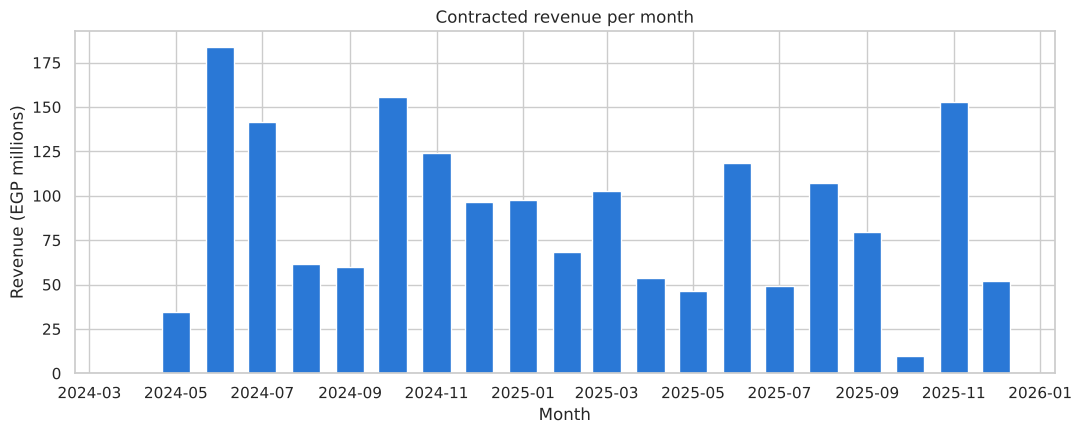

In [65]:
plt.figure(figsize=(11, 4.5))
plt.bar(monthly["month"], monthly["revenue"] / 1e6, width=20, color=BLUE)
plt.title("Contracted revenue per month")
plt.xlabel("Month")
plt.ylabel("Revenue (EGP millions)")
plt.tight_layout()
plt.show()

### Chart 2 – How fast is Phase 1 selling?
**Chart type:** line chart of the total units sold so far, with a grey line for the total number of units.
**Expected output:** a rising line well below the grey line.

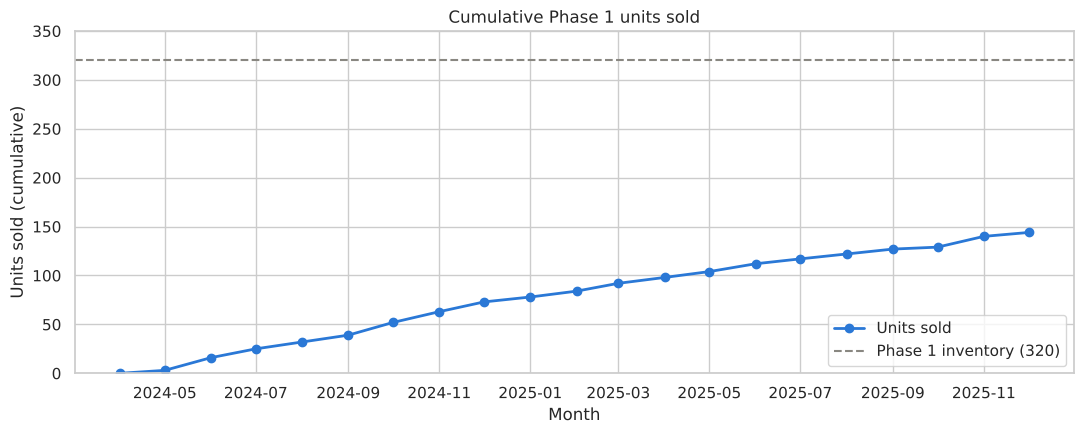

In [66]:
plt.figure(figsize=(11, 4.5))
plt.plot(monthly["month"], monthly["cumulative_units_sold"], color=BLUE, marker="o", linewidth=2, label="Units sold")
plt.axhline(len(p1), color=GREY, linestyle="--", label="Phase 1 inventory (320)")
plt.title("Cumulative Phase 1 units sold")
plt.xlabel("Month")
plt.ylabel("Units sold (cumulative)")
plt.ylim(0, 350)
plt.legend()
plt.tight_layout()
plt.show()

### Chart 3 – Which property types sell best?
**Chart type:** horizontal bar chart, sorted, so the types are easy to compare.
**Expected output:** sell-through % per type with the value next to each bar.

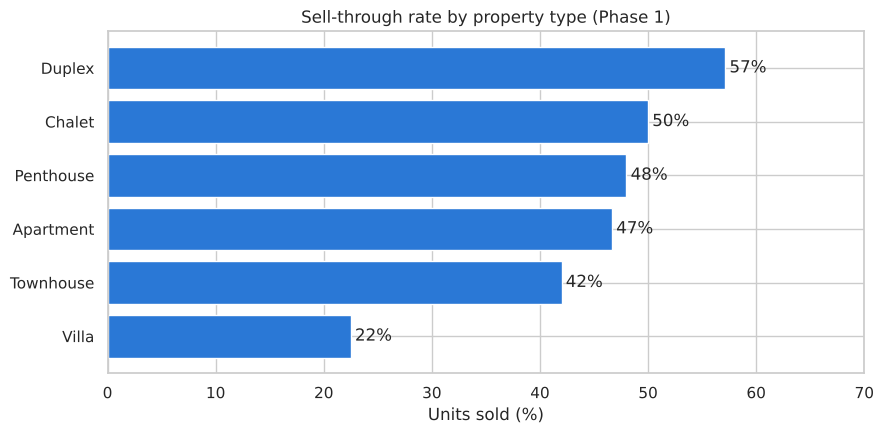

In [67]:
chart_data = by_type.sort_values("sell_through")

plt.figure(figsize=(9, 4.5))
bars = plt.barh(chart_data.index, chart_data["sell_through"] * 100, color=BLUE)
plt.bar_label(bars, fmt="%.0f%%", padding=3)
plt.title("Sell-through rate by property type (Phase 1)")
plt.xlabel("Units sold (%)")
plt.xlim(0, 70)
plt.tight_layout()
plt.show()

### Chart 4 – Does the price compared with similar units change the chance of selling?
**Chart type:** bar chart across the four price groups, from cheapest to most expensive for the type.
**Expected output:** four bars; the most expensive group is clearly the lowest.

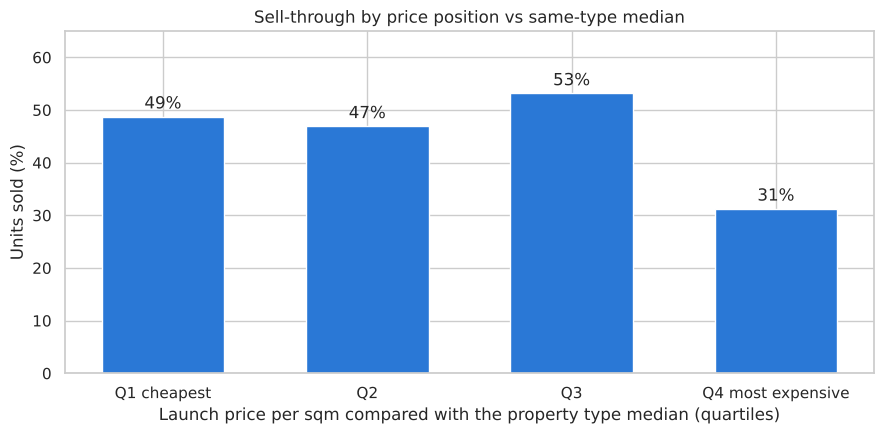

In [68]:
plt.figure(figsize=(9, 4.5))
bars = plt.bar(by_band.index.astype(str), by_band["sell_through"] * 100, color=BLUE, width=0.6)
plt.bar_label(bars, fmt="%.0f%%", padding=3)
plt.title("Sell-through by price position vs same-type median")
plt.xlabel("Launch price per sqm compared with the property type median (quartiles)")
plt.ylabel("Units sold (%)")
plt.ylim(0, 65)
plt.tight_layout()
plt.show()

### Chart 5 – Which features help sales?
**Chart type:** grouped bar chart – units **with** the feature (blue) vs **without** it (orange).
**Expected output:** pairs of bars; the bigger the gap, the more the feature matters.

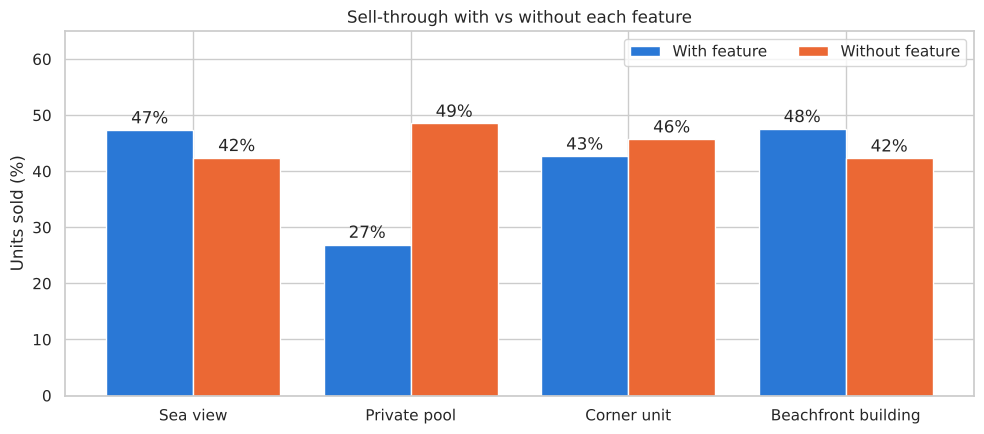

In [69]:
labels = ["Sea view", "Private pool", "Corner unit", "Beachfront building"]
x = np.arange(len(labels))

plt.figure(figsize=(10, 4.5))
bars_with = plt.bar(x - 0.2, feature_effect["with"] * 100, width=0.4, color=BLUE, label="With feature")
bars_without = plt.bar(x + 0.2, feature_effect["without"] * 100, width=0.4, color=ORANGE, label="Without feature")
plt.bar_label(bars_with, fmt="%.0f%%", padding=2)
plt.bar_label(bars_without, fmt="%.0f%%", padding=2)
plt.xticks(x, labels)
plt.title("Sell-through with vs without each feature")
plt.ylabel("Units sold (%)")
plt.ylim(0, 65)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

### Chart 6 – How are launch prices per sqm spread inside each type?
**Chart type:** box plot – shows the median, the middle 50% and the outliers.
**Expected output:** one box per type; Villas and Townhouses are the highest.

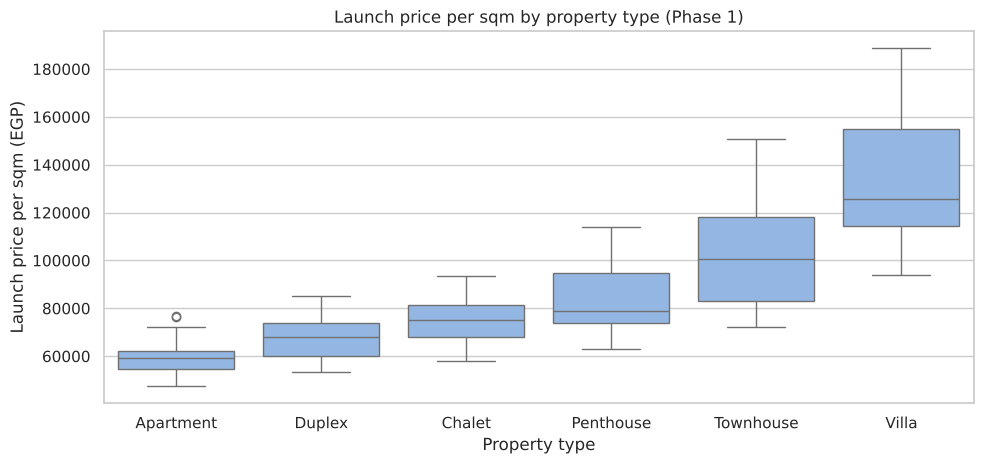

In [70]:
type_order = p1.groupby("property_type")["launch_price_per_sqm"].median().sort_values().index

plt.figure(figsize=(10, 4.8))
sns.boxplot(data=p1, x="property_type", y="launch_price_per_sqm", order=type_order, color="#86b6ef")
plt.title("Launch price per sqm by property type (Phase 1)")
plt.xlabel("Property type")
plt.ylabel("Launch price per sqm (EGP)")
plt.tight_layout()
plt.show()

### Chart 7 – How long does it take to sell a unit?
**Chart type:** histogram (the spread of one number), with the median as a dashed line.
**Expected output:** days from launch to reservation for the sold units.

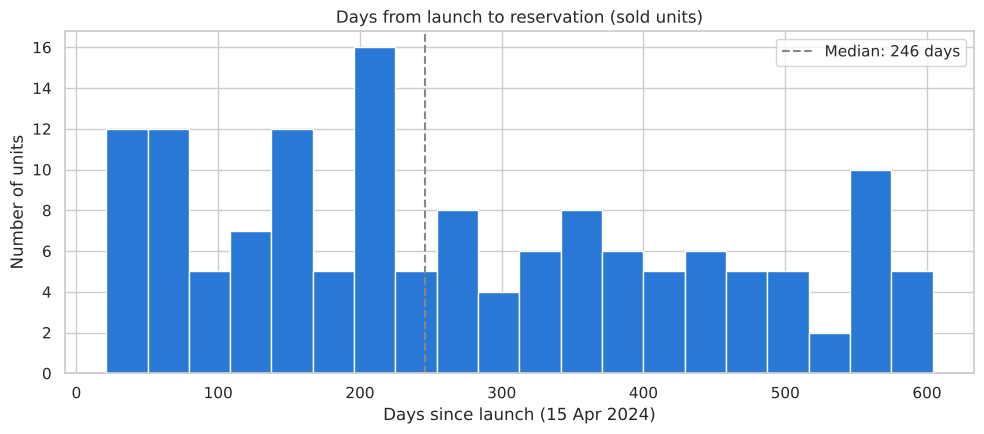

In [71]:
median_days = sales["days_to_sell"].median()

plt.figure(figsize=(10, 4.5))
plt.hist(sales["days_to_sell"], bins=20, color=BLUE, edgecolor="white")
plt.axvline(median_days, color=GREY, linestyle="--", label=f"Median: {median_days:.0f} days")
plt.title("Days from launch to reservation (sold units)")
plt.xlabel("Days since launch (15 Apr 2024)")
plt.ylabel("Number of units")
plt.legend()
plt.tight_layout()
plt.show()

### Chart 8 – Which lead channels bring volume, and which bring sales?
**Chart type:** two bar charts side by side. Lead count and conversion % use very different scales,
so each gets its own chart instead of one confusing chart with two y-axes.
**Expected output:** left = leads per channel, right = conversion % per channel.

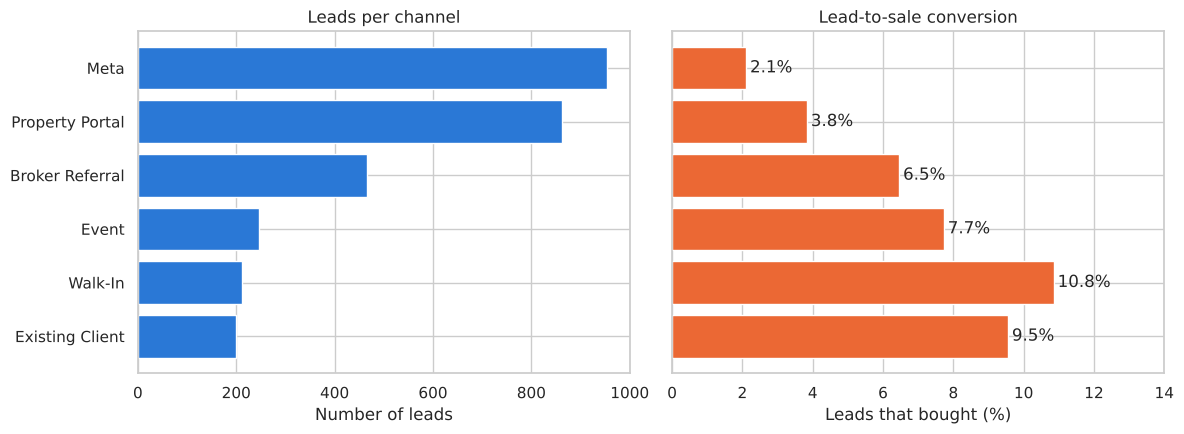

In [72]:
chart_data = by_source.sort_values("leads")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

ax1.barh(chart_data.index, chart_data["leads"], color=BLUE)
ax1.set_title("Leads per channel")
ax1.set_xlabel("Number of leads")

bars = ax2.barh(chart_data.index, chart_data["conversion"] * 100, color=ORANGE)
ax2.bar_label(bars, fmt="%.1f%%", padding=3)
ax2.set_title("Lead-to-sale conversion")
ax2.set_xlabel("Leads that bought (%)")
ax2.set_xlim(0, 14)

plt.tight_layout()
plt.show()

### Chart 9 – How are the numeric columns related?
**Chart type:** correlation heatmap. Blue = negative, white = no relationship, red = positive.
**Expected output:** a grid of correlations; look at the `is_sold` row.

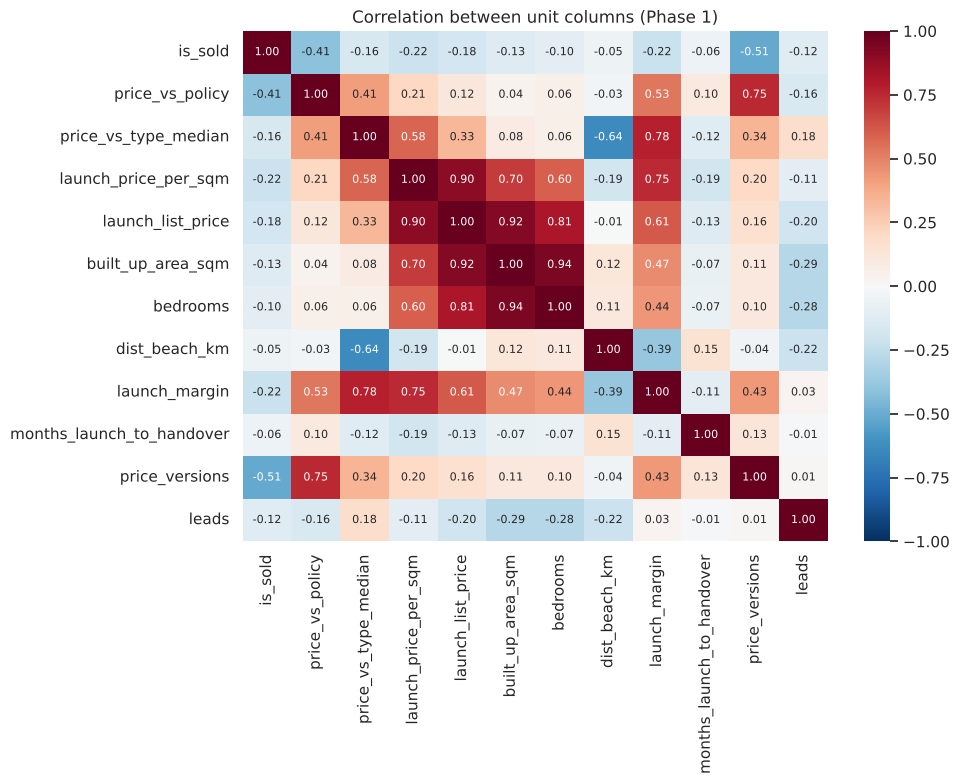

In [73]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 8})
plt.title("Correlation between unit columns (Phase 1)")
plt.tight_layout()
plt.show()

### Chart 10 – Is construction keeping up with the plan?
**Chart type:** line chart with two lines on the same % scale (actual vs planned).
**Expected output:** two rising lines; the gap between them is the delay.

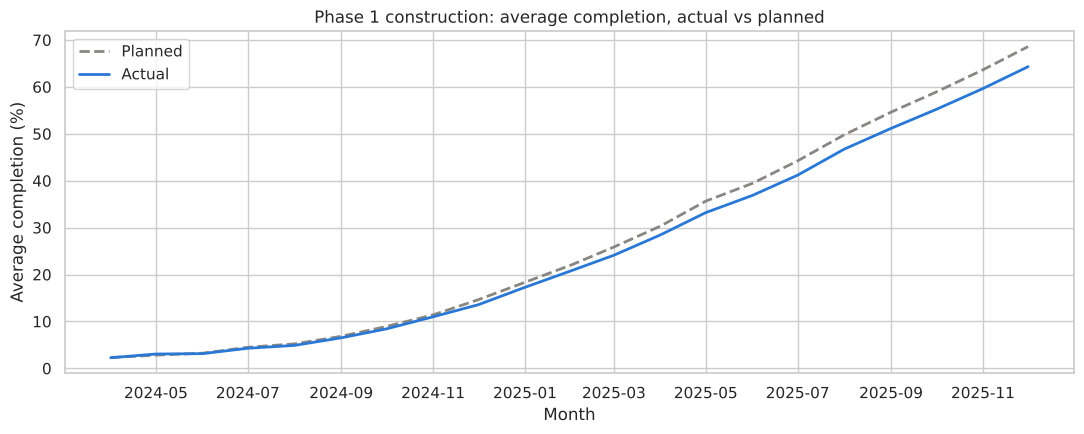

In [74]:
progress = pmo.groupby("report_month")[["construction_completion", "planned_completion"]].mean()

plt.figure(figsize=(11, 4.5))
plt.plot(progress.index, progress["planned_completion"], color=GREY, linestyle="--", linewidth=2, label="Planned")
plt.plot(progress.index, progress["construction_completion"], color=BLUE, linewidth=2, label="Actual")
plt.title("Phase 1 construction: average completion, actual vs planned")
plt.xlabel("Month")
plt.ylabel("Average completion (%)")
plt.legend()
plt.tight_layout()
plt.show()

### Chart 11 – How have market prices changed?
**Chart type:** line chart, one line per property type.
**Expected output:** six rising lines.

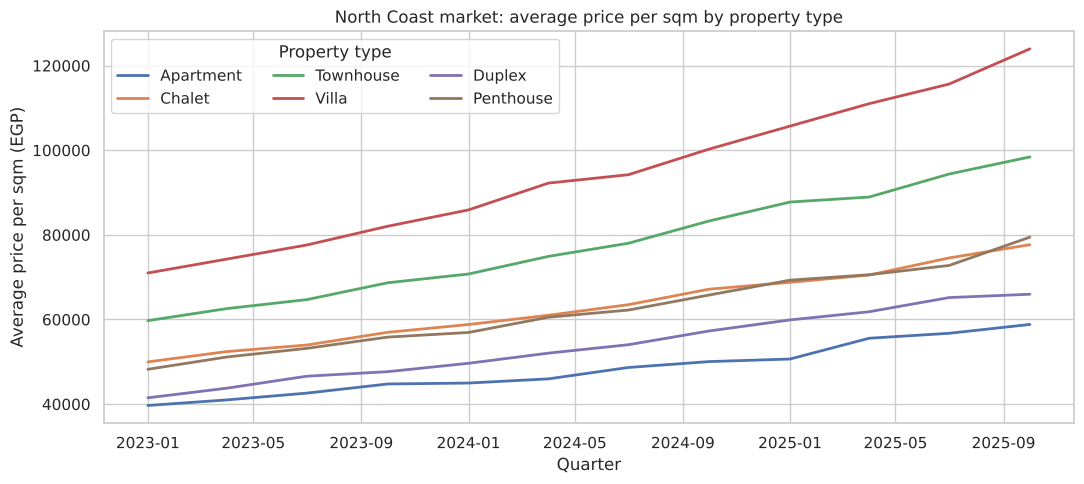

In [75]:
plt.figure(figsize=(11, 5))
sns.lineplot(data=price_index, x="quarter_start", y="average_price_per_sqm", hue="property_type", linewidth=2)
plt.title("North Coast market: average price per sqm by property type")
plt.xlabel("Quarter")
plt.ylabel("Average price per sqm (EGP)")
plt.legend(title="Property type", ncol=3)
plt.tight_layout()
plt.show()

### Chart 12 – Do launch prices respect the margin policy?
**Chart type:** bar chart of the median launch margin per type, with the policy minimum as a black line on each bar.
**Expected output:** every bar is well above its black line.

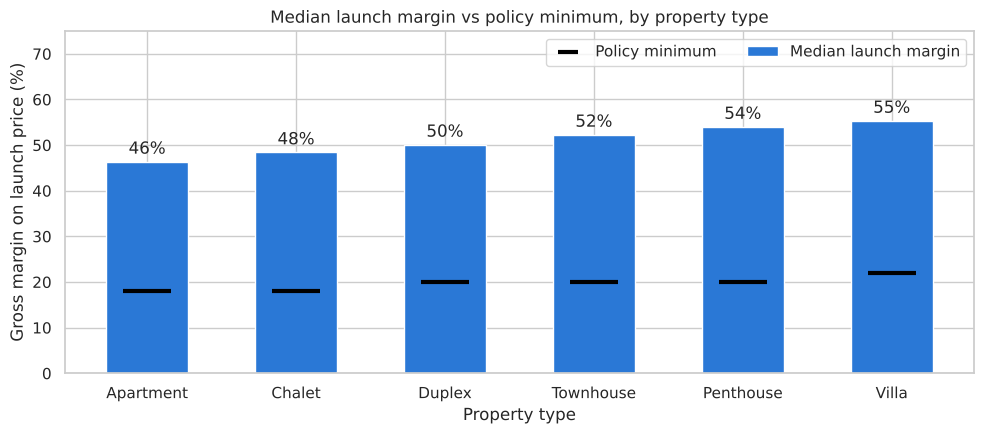

In [76]:
chart_data = margin_check.sort_values("median_margin")

plt.figure(figsize=(10, 4.5))
bars = plt.bar(chart_data.index, chart_data["median_margin"] * 100, color=BLUE, width=0.55, label="Median launch margin")
plt.scatter(chart_data.index, chart_data["minimum"] * 100, color="black", marker="_", s=1200, linewidths=3,
            label="Policy minimum")
plt.bar_label(bars, fmt="%.0f%%", padding=3)
plt.title("Median launch margin vs policy minimum, by property type")
plt.xlabel("Property type")
plt.ylabel("Gross margin on launch price (%)")
plt.ylim(0, 75)
plt.legend(ncol=2, markerscale=0.4)
plt.tight_layout()
plt.show()

# 8. Key findings and recommendations

All numbers come from the analysis above (Phase 1, report date 30 Dec 2025).

| # | Finding (evidence) | Recommendation |
|---|---|---|
| 1 | **Sales are slowing while 55% of stock is unsold.** 144 of 320 units (45%) sold for EGP 1.79B in 20 months. Sales peaked in 2024-Q4 (34) and have been about 6 per month since April 2025. At that speed the remaining 176 units need about 2.5 more years – well after handover (August 2026 to February 2027). | Set a monthly sales target linked to the handover date and track it on the dashboard. |
| 2 | **Villas are the main problem.** Villas sell 22% (9 of 40) vs 42–57% for every other type, and villas with a pool only 15% (4 of 27). Villas are the most expensive units, so each unsold villa ties up the most money. | Run a villa campaign: review pool-villa prices first and test longer payment plans for them. |
| 3 | **Being priced above the company's own policy price is the biggest sales killer.** Units launched at the policy price sold 74%; units about 15% above it sold only 16% (6.4b). The model in Section 9 confirms this is the #1 driver. Compared per sqm with similar units, the most expensive group sold 31% vs 47–53% and took a median 371 days vs 209–263. | Don't cut all prices. Use the policy price as the anchor and move the units furthest above it (about 12% or more) back toward it. |
| 4 | **There is room to cut prices within the policy.** The median launch margin is 49% (46–55% by type), well above the minimum (18–22%) and target (32–38%); no unit was launched below the minimum. | Targeted price cuts (finding 3) won't break the margin policy. *Note:* costs are budget rates without VAT. |
| 5 | **Long payment plans sell more and get better prices.** The 10%-down plans (6 and 8 years) and the 15%/7-year plan make 61% of sales; the 10%/8-year plan's median price is +3% vs list, while cash buyers pay –13% (the cash discount). | Promote long plans instead of cash discounts – they cost the company less per sale. |
| 6 | **The biggest lead channels convert the worst.** Meta brings the most leads (953, 32%) but only 2.1% buy; Property Portal 3.8%. Walk-ins (10.8%), existing clients (9.5%) and events (7.7%) convert 3–5× better. 147 leads have no broker. | Move some digital budget to events, referrals and existing-client offers; give every lead a broker within a day. |
| 7 | **The market has caught up with our prices.** At launch our median price per sqm was +31% above the market average. After 62% market growth in 3 years it is now about +1%. | Unsold units are now at market price. Keep prices on mid-priced units and only cut the overpriced ones. |
| 8 | **Construction is a bit behind plan.** In Dec 2025 Phase 1 is 64.3% built vs 68.6% planned (–4.3 pts), and all 28 buildings are behind; the worst is 8.7 pts behind. | Tell sales and buyers about the handover risk early. Delays could slow sales even more. |

**Limitations:** the data is synthetic; costs use budget rates and a ledger allocation, not actual spending; all Phase 1
units launched on the same day, but the analysis doesn't account for how long each unit has been on the market.

# 9. Machine learning model – will a unit sell?

### 9.1 Regression or classification?
The target is **`is_sold`**: 1 if the unit has a signed contract, 0 if not. It has only two possible values (yes / no),
so this is a **classification** problem, not regression (regression is for predicting a number, like a price).

**Business use:** before launching (or re-pricing) a unit, estimate how likely it is to sell at that price.

I train on the **320 Phase 1 units** only – Phase 2 is not on sale yet, so it has no answer to learn from.
I read the data back from `cleaned_data.csv`, so the model uses exactly the same file as the dashboard.
**Expected output:** how many units sold vs not sold, and the accuracy of a "dumb" model that always guesses the most common answer.

In [77]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import joblib

model_data = pd.read_csv(CLEAN_FILE)
model_data = model_data[model_data["phase"] == 1].copy()

print("Units:", len(model_data))
print(model_data["is_sold"].value_counts())
print(f"Always guessing 'not sold' would be right {1 - model_data['is_sold'].mean():.0%} of the time – the model must beat this.")

Units: 320
is_sold
0    176
1    144
Name: count, dtype: int64
Always guessing 'not sold' would be right 55% of the time – the model must beat this.


### 9.2 Choose the features and check for data leakage
**Rule:** a feature can only be used if it is **known on launch day**, before anyone buys. Otherwise the model "cheats"
by looking at information that only exists because the unit sold (or didn't) – this is called **data leakage**.

| Feature | Type | Why it is included |
|---|---|---|
| `price_vs_policy` | number | The strongest signal in the EDA: how far the launch price is above the policy price (6.4b) |
| `price_vs_type_median` | number | Price per sqm compared with similar units (6.4) |
| `built_up_area_sqm` | number | Size changes who can afford the unit |
| `dist_beach_km` | number | Distance to the beach – the main location factor in a beach resort |
| `property_type` | category | Villas sell much slower than Duplexes (6.2) |
| `sea_view`, `private_pool`, `beachfront` | category | The features with the biggest sell-through differences (6.3) |
| `default_plan` | category | The payment plan offered at launch – easier plans attract more buyers (6.9) |

**Why only 9 features?** I first tried **all 18** unit columns (bedrooms, bathrooms, plot area, cluster, view type, corner,
furnished status, other distances …). With only 320 units, the extra columns added noise and the models were no better
than guessing (see the comparison in 9.7). Keeping the 9 features with a clear link to selling works better.

**Left out because of leakage** (they are results of selling or not selling):
`current_list_price`, `price_versions`, `price_change_pct` (prices are cut *because* a unit doesn't sell),
`leads`, `viewings`, `reservations` (a sold unit always has a reservation), and every sale column
(`status`, `contract_*`, `reservation_date`, `days_to_sell`, `price_vs_list` …).

**Left out for other reasons:** `launch_list_price` and `launch_price_per_sqm` (their useful part is already inside the two
`price_vs_...` features) and the cost/margin columns (they are part of the policy price).

**Expected output:** the size of X (features) and y (target), and 0 missing values.

In [78]:
numeric_features = ["price_vs_policy", "price_vs_type_median", "built_up_area_sqm", "dist_beach_km"]
categorical_features = ["property_type", "sea_view", "private_pool", "beachfront", "default_plan"]

leakage_columns = ["current_list_price", "price_versions", "price_change_pct", "leads", "viewings", "reservations",
                   "status", "contract_date", "contract_price", "reservation_date", "days_to_sell", "price_vs_list"]

X = model_data[numeric_features + categorical_features].copy()
y = model_data["is_sold"]

print("X:", X.shape, "| y:", y.shape)
print("Missing values in X:", X.isna().sum().sum())
print("Any leakage column used?", any(col in X.columns for col in leakage_columns))

X: (320, 9) | y: (320,)
Missing values in X: 0
Any leakage column used? False


### 9.3 Train / test split (80 / 20)
**What:** 80% of the units are used to train the models, 20% are kept aside to test them on units they have never seen.
`random_state=42` makes the split the same every time I run the notebook.
`stratify=y` keeps the same share of sold units in both parts.
**Expected output:** 256 training units and 64 test units, both about 45% sold.

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, f"| sold: {y_train.mean():.0%}")
print("Test: ", X_test.shape, f"| sold: {y_test.mean():.0%}")

Train: (256, 9) | sold: 45%
Test:  (64, 9) | sold: 45%


### 9.4 Preprocessing with a Pipeline and ColumnTransformer
**What:**
- **Numbers** -> `StandardScaler` puts every number on the same scale (mean 0, standard deviation 1). Without it, a column
  in the tens of thousands (price per sqm) would dominate a column like bedrooms in Logistic Regression.
- **Categories** -> `OneHotEncoder` turns each category into 0/1 columns (for example `property_type_Villa`).
  `handle_unknown="ignore"` stops the model from crashing if the dashboard sends a category it has never seen.

**Why a Pipeline:** the preprocessing is learned from the training data only and is saved *inside* the model, so the
dashboard can send raw values and get the same transformation.
**Expected output:** nothing printed.

In [80]:
preprocessor = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_features),
    ("categories", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

### 9.5 Train two models
- **Logistic Regression** – the simple baseline. It draws a straight-line boundary and is easy to explain.
- **Random Forest** – a stronger model. It combines many decision trees and can learn non-linear patterns
  (for example "expensive *and* a villa"). I limit the tree depth (`max_depth=6`) and leaf size so it doesn't just memorise 256 units.

**Expected output:** nothing printed (the models are trained).

In [81]:
log_reg_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])

random_forest_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=5, random_state=42)),
])

log_reg_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)
print("Both models trained")

Both models trained


### 9.6 Compare the models on the test set
**Metrics (for the "sold" class):**
- **Accuracy** – share of all test units predicted correctly.
- **Precision** – of the units the model said *will sell*, how many really sold.
- **Recall** – of the units that really sold, how many the model found.
- **F1** – one number that balances precision and recall.
- **ROC AUC** – how well the model *ranks* units from likely to unlikely to sell (0.5 = random, 1.0 = perfect).

I also show **train accuracy**: if it is much higher than test accuracy, the model is memorising (overfitting).
**Expected output:** one row per model.

In [82]:
results = []
for name, model in [("Logistic Regression", log_reg_model), ("Random Forest", random_forest_model)]:
    predictions = model.predict(X_test)
    results.append({
        "model": name,
        "train_accuracy": accuracy_score(y_train, model.predict(X_train)),
        "test_accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions),
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]),
    })

results = pd.DataFrame(results).set_index("model")
results

,train_accuracy,test_accuracy,precision,recall,f1,roc_auc
model,,,,,,
Logistic Regression,0.75,0.59,0.55,0.55,0.55,0.65
Random Forest,0.81,0.62,0.63,0.41,0.50,0.66


### 9.7 Double-check with 5-fold cross-validation
**What:** the test set has only 64 units, so one lucky or unlucky split can change the scores a lot.
Cross-validation splits the data 5 different ways, trains 5 times and averages the scores.
`StratifiedKFold` with `shuffle=True` keeps 45% sold in every fold and uses the same 5 splits for every model.
**Expected output:** average accuracy, F1 and ROC AUC (± spread) for each model.

In [83]:
from sklearn.model_selection import StratifiedKFold

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for name, model in [("Logistic Regression", log_reg_model), ("Random Forest", random_forest_model)]:
    cv_accuracy = cross_val_score(model, X, y, cv=folds, scoring="accuracy")
    cv_f1 = cross_val_score(model, X, y, cv=folds, scoring="f1")
    cv_auc = cross_val_score(model, X, y, cv=folds, scoring="roc_auc")
    cv_results.append([name, cv_accuracy.mean(), cv_accuracy.std(), cv_f1.mean(), cv_auc.mean()])

cv_results = pd.DataFrame(cv_results, columns=["model", "cv_accuracy", "cv_accuracy_std", "cv_f1", "cv_roc_auc"]).set_index("model")
cv_results

,cv_accuracy,cv_accuracy_std,cv_f1,cv_roc_auc
model,,,,
Logistic Regression,0.70,0.04,0.66,0.75
Random Forest,0.68,0.04,0.61,0.73


### 9.7b Why I didn't use all 18 features
**What:** the same two models, trained on all 18 unit columns **without** `price_vs_policy` – my first attempt.
**Expected output:** accuracy of about 0.57–0.63 – only a little better than the 55% "always guess not sold" baseline, and clearly worse than the 9-feature models above (0.68–0.70).

In [84]:
all_numeric = ["bedrooms", "bathrooms", "built_up_area_sqm", "plot_area_sqm", "launch_price_per_sqm",
               "price_vs_type_median", "dist_beach_km", "dist_clubhouse_km", "months_launch_to_handover"]
all_categorical = ["property_type", "cluster", "beachfront", "view_type", "sea_view", "corner_unit",
                   "private_pool", "furnished_status", "default_plan"]

X_all = model_data[all_numeric + all_categorical].copy()
X_all["plot_area_sqm"] = X_all["plot_area_sqm"].fillna(0)   # no private plot = 0 sqm

preprocessor_all = ColumnTransformer([
    ("numbers", StandardScaler(), all_numeric),
    ("categories", OneHotEncoder(handle_unknown="ignore"), all_categorical),
])
first_attempts = [
    ("Logistic Regression", LogisticRegression(max_iter=1000)),
    ("Random Forest", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=5, random_state=42)),
]
for name, classifier in first_attempts:
    model = Pipeline([("preprocess", preprocessor_all), ("model", classifier)])
    score = cross_val_score(model, X_all, y, cv=folds, scoring="accuracy")
    print(f"First attempt – {name:<20} cv accuracy {score.mean():.2f}")

First attempt – Logistic Regression  cv accuracy 0.63
First attempt – Random Forest        cv accuracy 0.57


### 9.8 Confusion matrices
**What:** shows the 4 possible outcomes on the test set: correctly predicted *not sold*, correctly predicted *sold*,
and the two kinds of mistakes.
**Expected output:** two 2×2 grids, one per model.

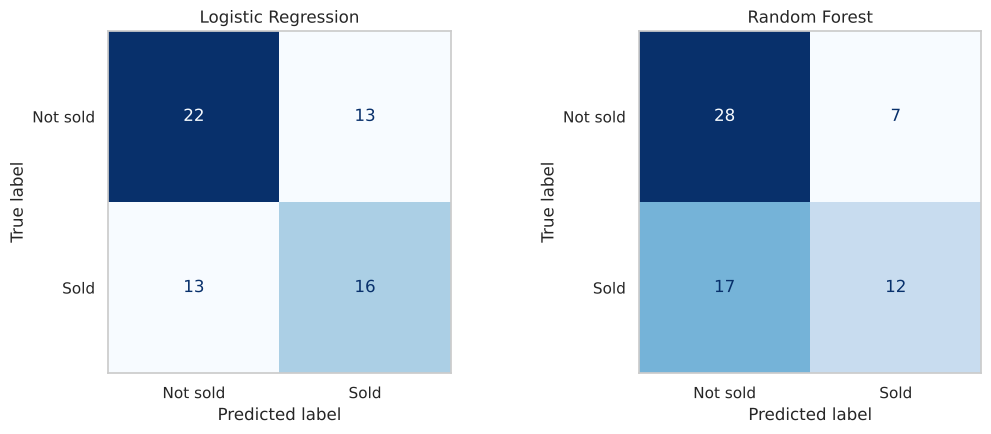

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, model) in zip(axes, [("Logistic Regression", log_reg_model), ("Random Forest", random_forest_model)]):
    matrix = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(matrix, display_labels=["Not sold", "Sold"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

### 9.9 Feature importance – Random Forest
**What:** how much each feature helped the Random Forest make its decisions (all importances add up to 1).
Category features appear once per value (for example `property_type_Villa`).
**Expected output:** a bar chart of the 15 most important features.

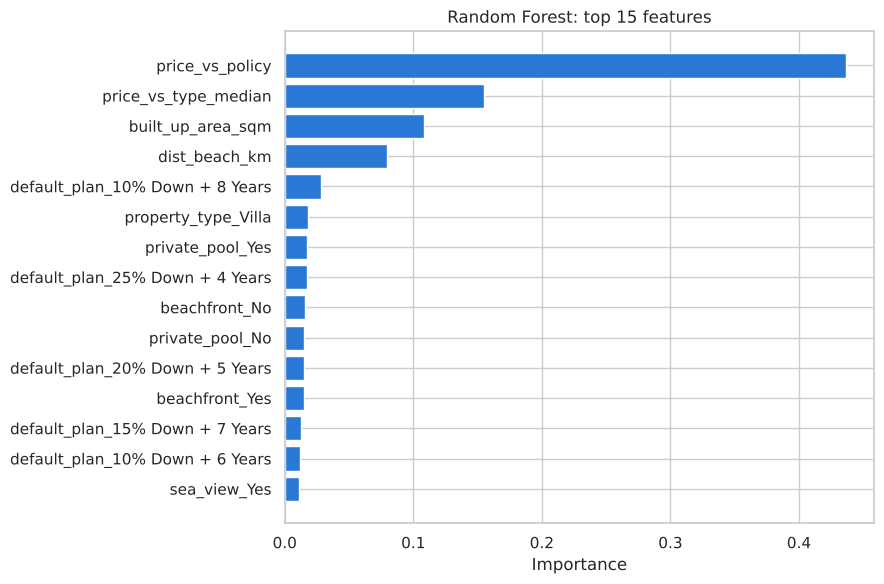

In [86]:
feature_names = random_forest_model.named_steps["preprocess"].get_feature_names_out()
feature_names = [name.split("__")[1] for name in feature_names]   # "numbers__bedrooms" -> "bedrooms"

importance = pd.DataFrame({
    "feature": feature_names,
    "importance": random_forest_model.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=False)

top_15 = importance.head(15).sort_values("importance")
plt.figure(figsize=(9, 6))
plt.barh(top_15["feature"], top_15["importance"], color=BLUE)
plt.title("Random Forest: top 15 features")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### 9.10 Direction of the effects – Logistic Regression coefficients
**What:** Random Forest importance says *how much* a feature matters, but not *in which direction*.
Logistic Regression coefficients do: a positive value makes selling **more** likely, a negative value **less** likely.
Because the numbers are scaled, the sizes can be compared.
**Expected output:** the 8 features that push most towards selling and the 8 that push most against.

In [87]:
coefficients = pd.DataFrame({
    "feature": feature_names,
    "coefficient": log_reg_model.named_steps["model"].coef_[0],
}).sort_values("coefficient")

print("Push towards NOT selling:")
display(coefficients.head(8))
print("Push towards SELLING:")
display(coefficients.tail(8).sort_values("coefficient", ascending=False))

Push towards NOT selling:


,feature,coefficient
0,price_vs_policy,-1.03
20,default_plan_25% Down + 4 Years,-0.64
9,property_type_Villa,-0.56
1,price_vs_type_median,-0.44
3,dist_beach_km,-0.36
19,default_plan_20% Down + 5 Years,-0.30
10,sea_view_No,-0.20
2,built_up_area_sqm,-0.06


Push towards SELLING:


,feature,coefficient
17,default_plan_10% Down + 8 Years,0.43
18,default_plan_15% Down + 7 Years,0.38
6,property_type_Duplex,0.21
7,property_type_Penthouse,0.20
11,sea_view_Yes,0.19
4,property_type_Apartment,0.13
16,default_plan_10% Down + 6 Years,0.13
12,private_pool_No,0.05


### 9.11 Which model I keep, what it tells us, and its limits

**Model comparison**

| | Logistic Regression | Random Forest |
|---|---|---|
| CV accuracy (5 folds, all 320 units) | **0.70** | 0.68 |
| CV F1 | **0.66** | 0.61 |
| CV ROC AUC | **0.75** | 0.73 |
| Test accuracy (64 units) | 0.59 | 0.62 |
| Test recall (sold units found) | **0.55** (16 of 29) | 0.41 (12 of 29) |
| Train accuracy | 0.75 | 0.81 |

**I keep Logistic Regression**, because:
- it is better on all three cross-validation scores, which use all 320 units and are more reliable than one 64-unit test set;
- it finds more of the units that really sell. Random Forest's slightly higher test accuracy comes from predicting
  "not sold" more often – it misses 17 of the 29 sold units;
- it overfits less (smaller gap between train and test accuracy), and its coefficients are easy to explain.

The test scores are lower than the CV scores for both models. This 64-unit split happened to be harder than average,
which is why I trust the 5-fold average more.

**What drives a sale (plain English)**
1. **Price compared with the policy price is by far the biggest driver.** It is the top Random Forest feature (about 0.44 of
   all importance) and the strongest Logistic Regression coefficient (–1.03). The further a unit is priced above what the
   company's own rules say, the less likely it sells.
2. **Price per sqm compared with similar units, and distance to the beach,** come next. More expensive and further from the beach = less likely to sell.
3. **Payment plan matters.** The easy plans (10% down / 8 years, 15% down / 7 years) push towards selling; the hard ones
   (25% / 4 years, 20% / 5 years) push against.
4. **Villas** are less likely to sell, even after taking price into account. A sea view helps a little.
5. **A private pool has almost no effect once price is included** (coefficient about ±0.05). This confirms 6.3b: the low sales
   of pool units are mostly a price problem, not a pool problem.

**Limitations**
- **Small data:** 320 units, so the scores move by about ±0.04 between folds. About 3 out of 10 predictions are wrong –
  use the model to **rank units by risk**, not as a guarantee.
- **It only knows launch-day facts.** It doesn't know about marketing, broker effort, later price changes or market movements after launch.
- **The policy price depends on assumptions:** budget costs (not actual spending, no VAT) and the beach-proximity rule from 4.6b.
- **Time:** it learned from 2024 launch prices, and the market has moved about 60% since 2023. It should be retrained
  before it is used for Phase 2 prices.
- The data is synthetic, so the exact numbers would change with real data.

### 9.12 Save the best model
**What:** saves the whole chosen pipeline (preprocessing + model) to `models/model.joblib`, then loads it back and checks
it gives the same predictions – this is the file the Streamlit dashboard will use.
**Expected output:** the saved path and `True`.

In [88]:
best_model = log_reg_model   # chosen in 9.11
joblib.dump(best_model, "models/model.joblib")

loaded_model = joblib.load("models/model.joblib")
print("Saved to models/model.joblib")
print("Same predictions after loading:", (loaded_model.predict(X_test) == best_model.predict(X_test)).all())

example = X_test.head(3)
print("Probability of selling for 3 test units:", loaded_model.predict_proba(example)[:, 1].round(2))

Saved to models/model.joblib
Same predictions after loading: True
Probability of selling for 3 test units: [0.41 0.4  0.25]


---
**End of Step 3.** Next: the Streamlit dashboard (`app.py`) that uses `data/cleaned_data.csv` and `models/model.joblib`.